# Avance 2: análisis de asociaciones y modelamiento estadístico

Proyecto: factores asociados a la duración de la estadía hospitalaria en beneficiarios FONASA (Chile, 2020). Este notebook acompaña al informe final (`paper/informe_v5.tex`) y calcula todas sus cifras, tablas y figuras a partir de los datos abiertos del DEIS.

Es un estudio observacional y analítico. Todos los modelos se estiman con los 968.098 egresos de la base completa, y las medidas de ajuste ($R^2$, BIC) describen esta población. Las asociaciones se leen a través de coeficientes, intervalos de confianza, pruebas $F$ y $t$ y tamaños de efecto ($\eta^2$ parcial). El modelo es una regresión lineal múltiple de ln(días); la estadía prolongada (más de 15 días) solo se usa para describir la concentración de días-cama y en las pruebas chi-cuadrado de a pares.

Fuente de todas las tablas y figuras: DEIS (MINSAL), egresos hospitalarios 2020; elaboración propia.

### Correspondencia entre el informe y el notebook

| Informe | Contenido | Sección del notebook |
|---|---|---|
| Resumen e introducción | n, 9,4 % de egresos y 47,1 % de días-cama, $R^2$, $\eta^2$ parcial, hipótesis | 1, Etapa 1, 3.2 y síntesis numérica |
| Figura 1 | Diagrama metodológico | sin código: está dibujado en el informe |
| Sección 3.2 (datos) | 397 excluidos, máximo de 16.598 días | Paso 1 |
| Sección 3.3 y tabla 1 | Revisión de columnas y variables del estudio | Revisión de las columnas y Etapa 2 |
| Tabla 2 | Hipótesis de cada prueba | sin código: es la definición de las pruebas |
| Sección 4.1, tabla 3 y figura 2 | Descriptivos, distribución de los días, nulos, Tukey, MAD y filtro de 365 días | Etapas 1, 3 y 4 |
| Sección 4.2, tabla 4 y anexo A | Normalidad, 20 pruebas de a pares, post hoc de Holm, V de Cramér, gráficos y tablas de contingencia | Etapa 5 y pruebas de asociación de a pares |
| Figura 3 | ln(días) por capítulo, establecimiento y sexo | Etapa 5 |
| Sección 4.3 y tabla 5 | Modelos anidados M0 a M3 | 3.2 |
| Sección 4.4, tabla 6 y anexo B | ANOVA, F por factor, coeficientes con EE clásico y HC3, figura forest | 3.3 |
| Sección 4.5 y anexo C | Deciles, rango, VIF, residuos, edad observada y ajustada | 3.4 a 3.6 |
| Sección 4.6 y anexo D | Especificaciones M3 a M6, nacionalidad y etnia, selección forward | 3.8 y 3.9 |
| Sección 4.7 y tabla 7 | Ranking por $\eta^2$ parcial y orden forward | 3.2 y 3.9 |
| Sección 5 y tabla 8 | Contraste de las hipótesis, literatura, limitaciones | 4 |


## 1. Pregunta de investigación e hipótesis

> ¿Qué factores clínicos, demográficos y del sistema de salud se asocian con la duración de la estadía en los egresos FONASA de Chile en 2020?

Llamamos prolongada a una estadía de más de 15 días, el percentil 90 de la duración, así que por construcción cerca de uno de cada diez egresos queda como prolongado. Ese corte solo se usa para describir la concentración de días-cama y en las pruebas chi-cuadrado de a pares.

**Hipótesis general**

- H₀: la duración de la estadía no se asocia con los factores clínicos, demográficos ni del sistema de salud.
- H₁: al menos uno de esos factores se asocia con la duración de la estadía.

La separamos en una hipótesis por grupo de factores. En cada una, la nula dice que ningún factor del grupo se asocia con la duración una vez que los demás factores se mantienen constantes, y la alternativa dice que al menos uno sí se asocia.

| | Factores | Prueba en M3 |
|---|---|---|
| H₀a y H₁a (clínicos) | Capítulo del diagnóstico (CIE-10), cirugía y condición de egreso | F parcial de cada factor |
| H₀b y H₁b (demográficos) | Edad y sexo; esperamos más días a mayor edad | t de la edad y F del sexo |
| H₀c y H₁c (sistema de salud) | Tipo de establecimiento y región | F parcial de cada factor |
| H₀d y H₁d (sensibilidad) | Nacionalidad y etnia, que la selección por BIC dejó fuera; la nula dice que no agregan asociación a los siete factores anteriores | F parcial al agregarlas a M3 |

Usamos α = 0,05. Con casi un millón de egresos rechazar es casi seguro, así que además ordenamos los factores por su tamaño de efecto ajustado ($\eta^2$ parcial) y consideramos relevante un factor con $\eta^2$ parcial ≥ 0,01.

## 2. Exploración y preparación de los datos

Seguimos cinco etapas: análisis descriptivo, ajuste de variables, valores nulos, valores atípicos y relación entre variables.

### Paso 1: cargar los datos

Incluimos FONASA (`PREVISION = 1`) y estadías de hasta 365 días, manteniendo el criterio del Avance 1. Se excluyen 397 registros de más de un año por la regla de depuración adoptada; la duración por sí sola no demuestra que todos sean errores. Se conservan las estadías largas dentro del rango definido porque forman parte del fenómeno de interés.

In [1]:
import os
import json
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
from IPython.display import Markdown, display
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.outliers_influence import variance_inflation_factor

import sys
from statsmodels.stats.diagnostic import lilliefors
from statsmodels.stats.multitest import multipletests
from matplotlib import font_manager as fm
_fuentes = [os.path.expanduser(f"~/.fonts/{f}") for f in ("Figtree-Regular.ttf", "Figtree-Medium.ttf")]
if all(os.path.exists(f) for f in _fuentes):          # Figtree, como en el informe; si no está, matplotlib usa su fuente por defecto
    for f in _fuentes:
        fm.fontManager.addfont(f)
    plt.rcParams["font.family"] = "Figtree"
plt.rcParams.update({"font.size":7.5,"axes.labelsize":7.5,"xtick.labelsize":6.8,"ytick.labelsize":6.8,"legend.fontsize":6.8,"axes.titlesize":8,"lines.linewidth":1.1,"lines.markersize":3.2,"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3, "pdf.fonttype": 42})
teal, petroleo, coral = "#0E7C7A", "#0F2A33", "#D9534F"
sys.path.insert(0, "paper")
import figuras                                       # código de todas las figuras del informe (paper/figuras.py)
def es(x, d=1, signo=False):                      # número con coma decimal y punto de miles
    return f"{x:{'+' if signo else ''},.{d}f}".translate(str.maketrans(",.-", ".,−"))

with zipfile.ZipFile("data/raw/EGRESOS_2020.zip") as z:
    df = pd.read_csv(z.open("EGRE_DATOS_ABIERTOS_2020.csv"), sep=";", encoding="cp1252", dtype=str)
n_columnas = df.shape[1]
print("Egresos 2020:", len(df), "| columnas:", n_columnas)

df = df[df["PREVISION"] == "1"]                      # solo FONASA
df["dias_estada"] = pd.to_numeric(df["DIAS_ESTADA"])
bruta = df["dias_estada"].copy()                     # con los de más de 365 días, para compararlos en la etapa 4
print("Estadías de más de 365 días:", (df["dias_estada"] > 365).sum(), "| máximo:", df["dias_estada"].max(), "días")
df = df[df["dias_estada"] <= 365].copy()             # regla de depuración del Avance 1
print("Egresos FONASA con estada <= 365 días:", len(df))

Egresos 2020: 1330477 | columnas: 18


Estadías de más de 365 días: 397 | máximo: 16598 días
Egresos FONASA con estada <= 365 días: 968098


### Revisión de las columnas

La base trae una fila por egreso. Revisamos cada columna con tres condiciones: que su significado esté en el diccionario del DEIS o se pueda verificar con los datos, que varíe entre egresos y que no repita otra columna. `INTERV_Q` y `PROCED` no aparecen en el diccionario. Si `INTERV_Q = 1` indica cirugía, debería aparecer en casi todas las cesáreas y apendicitis y en pocos partos normales.

In [2]:
print("Columnas de la base original:", n_columnas)
print("Egresos FONASA excluidos por más de 365 días:", int((bruta > 365).sum()), f"({100 * (bruta > 365).mean():.2f} % de los egresos FONASA)")
print("Percentil 90 de los días de estada:", df["dias_estada"].quantile(0.9))
n_comunas = df["COMUNA_RESIDENCIA"].nunique()
print("Comunas:", n_comunas, "| comunas que aparecen en más de una región:",
      int((df.groupby("COMUNA_RESIDENCIA")["REGION_RESIDENCIA"].nunique() > 1).sum()))
print("ln(n), costo de cada coeficiente en el BIC:", round(np.log(len(df)), 2))
diagnosticos = {"Cesárea (O82)": "O82", "Apendicitis (K35)": "K35", "Colelitiasis (K80)": "K80", "Parto normal (O80)": "O80"}
filas = []
for nombre, codigo in diagnosticos.items():
    grupo = df[df["DIAG1"].str[:3] == codigo]
    filas.append({"diagnóstico": nombre, "egresos": len(grupo),
                  "% INTERV_Q = 1": 100 * (grupo["INTERV_Q"] == "1").mean(),
                  "% PROCED = 1": 100 * (grupo["PROCED"] == "1").mean()})
tabla_intervq = pd.DataFrame(filas).set_index("diagnóstico")
tabla_intervq.round(1)

Columnas de la base original: 18
Egresos FONASA excluidos por más de 365 días: 397 (0.04 % de los egresos FONASA)
Percentil 90 de los días de estada: 15.0
Comunas: 344 | comunas que aparecen en más de una región: 0
ln(n), costo de cada coeficiente en el BIC: 13.78


,egresos,% INTERV_Q = 1,% PROCED = 1
diagnóstico,,,
Cesárea (O82),48185,97.2,3.5
Apendicitis (K35),23298,91.2,3.6
Colelitiasis (K80),32118,76.0,10.9
Parto normal (O80),48208,3.2,41.2


`INTERV_Q = 1` aparece en el 97,2 % de las cesáreas y en el 91,2 % de las apendicitis, y solo en el 3,2 % de los partos normales, así que la usamos como cirugía. `PROCED` vale 1 en el 41,2 % de los partos normales y en el 3,5 % de las cesáreas. Como no pudimos verificar qué registra, la descartamos. `COMUNA_RESIDENCIA` tiene 344 categorías y cada comuna pertenece a una sola región, así que repite la región. El percentil 90 de la duración es 15 días, el umbral que usamos para definir la estadía prolongada. Cada coeficiente cuesta ln(968.098) ≈ 13,8 en el BIC.

Quedan 968.098 egresos, el mismo número del Avance 1.

### Paso 2: construir las variables

Reutilizamos los mapeos del Avance 1: la edad es el punto medio de cada tramo, el capítulo CIE-10 viene del diccionario del DEIS, `INTERV_Q` 1/2 es cirugía Sí/No y `CONDICION_EGRESO` 1/2 es vivo/fallecido. Nos quedamos con la respuesta, las 7 variables explicativas y `DIAG2` (para revisar sus nulos), y agregamos ln(días).

In [3]:
edad_media = {"menor de un año": 0.5, "1 a 9": 5, "10 a 19": 14.5, "20 a 29": 24.5, "30 a 39": 34.5,
              "40 a 49": 44.5, "50 a 59": 54.5, "60 a 69": 64.5, "70 a 79": 74.5, "80 a 89": 84.5,
              "90 y más": 92.5}
cie = pd.read_excel("data/raw/x2020/Diccionario BD egresos hospitalario.xlsx", "codigo CIE-10", header=8)
cie.columns = cie.columns.str.strip()

df["prolongada"] = np.where(df["dias_estada"] > 15, "Sí", "No")
df["edad"] = df["GRUPO_EDAD"].map(edad_media)
df["tramo_edad"] = df["GRUPO_EDAD"]
df["sexo"] = df["SEXO"]
df["capitulo"] = df["DIAG1"].map(dict(zip(cie["CODIGO SUBCATEGORIA"], cie["CAPITULO"])))
df["capitulo"] = df["capitulo"].fillna(df["DIAG1"].str[:3].map(dict(zip(cie["CODIGO CATEGORIA"], cie["CAPITULO"]))))
df["cirugia"] = df["INTERV_Q"].map({"1": "Sí", "2": "No"})
df["fallecido"] = df["CONDICION_EGRESO"].map({"1": "No", "2": "Sí"})
df["establecimiento"] = np.where(df["PERTENENCIA_ESTABLECIMIENTO_SALUD"].str.startswith("Pert"), "SNSS", "No SNSS")
df["region"] = df["GLOSA_REGION_RESIDENCIA"]
df["nacionalidad"] = df["GLOSA_PAIS_ORIGEN"]
df["etnia"] = np.where(df["ETNIA"].str.startswith("Si"), "Sí", "No")
df["log_dias"] = np.log(df["dias_estada"])

variables = ["dias_estada", "log_dias", "prolongada", "edad", "tramo_edad", "sexo", "capitulo", "cirugia",
             "fallecido", "establecimiento", "region", "nacionalidad", "etnia", "DIAG2"]
df = df[variables]
print("Egresos:", len(df), "| columnas:", df.shape[1])
df.head()

Egresos: 968098 | columnas: 14


,dias_estada,log_dias,prolongada,edad,tramo_edad,sexo,capitulo,cirugia,fallecido,establecimiento,region,nacionalidad,etnia,DIAG2
0,1,0.0,No,5.0,1 a 9,HOMBRE,Q00-Q99,Sí,No,No SNSS,De Tarapacá,Chileno,No,NaN
1,1,0.0,No,5.0,1 a 9,HOMBRE,Q00-Q99,Sí,No,No SNSS,De Tarapacá,Chileno,No,NaN
2,1,0.0,No,5.0,1 a 9,HOMBRE,Z00-Z99,Sí,No,No SNSS,De Tarapacá,Chileno,No,NaN
3,1,0.0,No,5.0,1 a 9,HOMBRE,N00-N99,Sí,No,No SNSS,De Tarapacá,Chileno,No,NaN
4,1,0.0,No,5.0,1 a 9,HOMBRE,N00-N99,Sí,No,No SNSS,De Tarapacá,Chileno,No,NaN


### Etapa 1: análisis descriptivo

**Tabla 3 (informe).** Estadísticos descriptivos de los días de estada, ln(días) y la edad. Fuente: DEIS, MINSAL, egresos hospitalarios 2020; elaboración propia.

In [4]:
cols = ["dias_estada", "log_dias", "edad"]
desc = df[cols].agg(["count", "mean", "median"]).T
desc["Q1"] = df[cols].quantile(0.25)
desc["Q3"] = df[cols].quantile(0.75)
desc["RIC"] = desc["Q3"] - desc["Q1"]
desc["s"] = df[cols].std()
desc["CV"] = desc["s"] / desc["mean"]
desc["asimetría"] = df[cols].skew()
desc.round(2)

,count,mean,median,Q1,Q3,RIC,s,CV,asimetría
dias_estada,968098.0,6.70,3.0,2.00,7.00,5.00,12.79,1.91,9.04
log_dias,968098.0,1.25,1.1,0.69,1.95,1.25,1.04,0.83,0.68
edad,968098.0,45.01,44.5,24.50,64.50,40.00,24.29,0.54,0.01


Los días de estada tienen media 6,70 y mediana 3 (Q1 = 2, Q3 = 7, RIC = 5). La desviación estándar (12,79) casi duplica la media (CV = 1,91) y la asimetría es 9,04: la mayoría dura pocos días y unos pocos duran muchísimo. En ln(días) la asimetría baja a 0,68 y la media (1,25) queda cerca de la mediana (1,10), por eso modelamos el logaritmo. La edad es simétrica (asimetría 0,01; media 45,01; mediana 44,5; Q1 = 24,5; Q3 = 64,5).

In [5]:
for var in ["establecimiento", "sexo"]:
    print((100 * df[var].value_counts(normalize=True)).round(1).to_string(), "\n")
cap = 100 * df["capitulo"].value_counts(normalize=True)
print("Capítulos más frecuentes (%):")
print(cap.head(6).round(1).to_string())
print(f"Los otros {len(cap) - 6} capítulos juntos:", round(cap.iloc[6:].sum(), 1), "%")

establecimiento
SNSS       81.8
No SNSS    18.2 

sexo
MUJER     60.0
HOMBRE    40.0 

Capítulos más frecuentes (%):
capitulo
O00-O99    20.4
K00-K93    13.8
S00-T98     9.8
I00-I99     9.3
N00-N99     7.6
C00-D48     7.4
Los otros 15 capítulos juntos: 31.7 %


El 81,8 % de los egresos son de establecimientos del SNSS y el 60,0 % son mujeres. Los capítulos más frecuentes son embarazo, parto y puerperio (O00-O99, 20,4 %), digestivo (K00-K93, 13,8 %) y traumatismos (S00-T98, 9,8 %). Los otros 15 suman el 31,7 %.

**Figura 2 (informe).** Distribución de los días de estada (izquierda, recortada a 60 días), de ln(días) (centro) y curva de concentración de los días-cama (derecha).

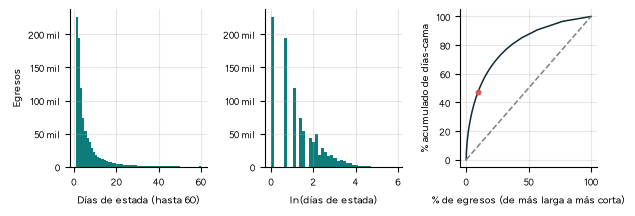

Media: 6.7 | mediana: 3.0 | egresos prolongados: 9.4 % | días-cama que usan: 47.1 %


In [6]:
largas = df["prolongada"] == "Sí"
pct_egresos = 100 * largas.mean()
pct_dias = 100 * df.loc[largas, "dias_estada"].sum() / df["dias_estada"].sum()

fig = figuras.distribucion(df["dias_estada"], df["log_dias"], pct_egresos, pct_dias)
figuras.guardar(fig, "avance2_distribucion", png=True)
plt.show()
print("Media:", round(df["dias_estada"].mean(), 1), "| mediana:", df["dias_estada"].median(),
      "| egresos prolongados:", round(pct_egresos, 1), "% | días-cama que usan:", round(pct_dias, 1), "%")

El histograma de días tiene cola larga: la moda es 1 día (226.248 egresos), seguida de 2 días (194.873) y 3 días (119.440). En ln(días) las barras quedan separadas porque los días son enteros (ln 1 = 0, ln 2 = 0,69, ln 3 = 1,10), y la cola derecha es más corta. La curva de la derecha muestra que el 9,4 % de los egresos (los de más de 15 días) usa el 47,1 % de los días-cama (estadías de hasta 365 días). Esos pocos egresos largos pesan mucho en la gestión de camas, así que queremos entender qué se asocia con la duración.

### Etapa 2: ajuste de variables

| Variable | Tipo | Codificación | Referencia |
|---|---|---|---|
| ln(días) | Numérica, respuesta | Logaritmo natural de `DIAS_ESTADA` | |
| Edad | Numérica | `edad_c` = punto medio del tramo − media, y `edad_c`² | Edad media (0) |
| Capítulo CIE-10 | Categórica (21) | 20 indicadoras | K00-K93 |
| Cirugía | Categórica | Indicadora de Sí | No |
| Condición de egreso | Categórica | Indicadora de fallecido | Vivo |
| Sexo | Categórica | Indicadora de hombre | Mujer |
| Establecimiento | Categórica | Indicadora de SNSS | No SNSS |
| Región | Categórica (16) | 15 indicadoras | Metropolitana de Santiago |

En el Avance 1 centramos la edad en 50 para que edad y edad² no quedaran colineales en la selección por BIC. Aquí la centramos en su media, así el intercepto corresponde a un paciente de edad promedio. Es solo un cambio de origen y el ajuste es el mismo.

En sexo la referencia es la mujer, para expresar el coeficiente como hombres frente a mujeres. Así respondemos lo que el Avance 1 dejó pendiente: si la diferencia por sexo se mantiene al controlar por diagnóstico. La asociación ajustada se estima en 3.3 con la base completa. Cambiar la referencia solo cambia el signo y la lectura del coeficiente.

Como capítulo de referencia usamos K00-K93 en vez de O00-O99, que en el Avance 1 usamos solo para la selección. O00-O99 contiene solo mujeres. K00-K93 ofrece una referencia clínicamente común en ambos sexos; cambiar la referencia no modifica el ajuste ni resuelve por sí mismo la asociación entre sexo y capítulo. K00-K93 tiene hombres y mujeres y una mediana baja (2 días), así que los demás coeficientes son diferencias respecto de un egreso corto y habitual.

In [7]:
edad_prom = df["edad"].mean()
df["edad_c"] = df["edad"] - edad_prom
print("Edad media (el cero de edad_c):", round(edad_prom, 2))
k = df[df["capitulo"] == "K00-K93"]
print("Capítulo K00-K93:", round(100 * len(k) / len(df), 1), "% de los egresos | mediana:", k["dias_estada"].median(),
      "días | sexo (% mujeres):", round(100 * (k["sexo"] == "MUJER").mean(), 1))
print("Valores de sexo:", sorted(df["sexo"].unique()))

Edad media (el cero de edad_c): 45.01
Capítulo K00-K93: 13.8 % de los egresos | mediana: 2.0 días | sexo (% mujeres): 53.6
Valores de sexo: ['HOMBRE', 'MUJER']


La edad media es 45,01 años. K00-K93 es el 13,8 % de los egresos, con una mediana de 2 días y un 53,6 % de mujeres, así que sirve como referencia para interpretar comparaciones.

### Etapa 3: valores nulos

In [8]:
usadas = ["dias_estada", "edad", "sexo", "capitulo", "cirugia", "fallecido", "establecimiento", "region", "DIAG2"]
print(df[usadas].isna().sum().to_string())
pct_diag2 = 100 * df["DIAG2"].isna().mean()
print("DIAG2 nulo:", round(pct_diag2, 1), "% de los egresos")

dias_estada             0
edad                    0
sexo                    0
capitulo                0
cirugia                 0
fallecido               0
establecimiento         0
region                  0
DIAG2              872823
DIAG2 nulo: 90.2 % de los egresos


Las variables de la respuesta y de las 7 variables explicativas no tienen nulos, así que no imputamos ni eliminamos egresos. `DIAG2` tiene un 90,2 % de nulos. En el Avance 1 vimos que solo aparece en el capítulo S00-T98, con una V de Cramér de 1,00: repite información del capítulo. Por eso la descartamos.

### Etapa 4: valores atípicos

Usamos el criterio de Tukey (Ls = Q3 + 1,5·RIC) y el de |z| > 3, sobre días y ln(días). Comparamos también media y desviación estándar con mediana y MAD (mediana de las desviaciones absolutas respecto de la mediana), antes y después del filtro de 365 días.

**Tabla complementaria.** Límites de Tukey y de |z| > 3 para los días y ln(días) (primera salida). **Tabla complementaria.** Media, desviación estándar, mediana y MAD antes y después de excluir los egresos de más de 365 días (segunda salida). Fuente: DEIS, MINSAL, egresos hospitalarios 2020; elaboración propia.

In [9]:
filas = []
for nombre, x in [("días", df["dias_estada"]), ("ln(días)", df["log_dias"])]:
    q1, q3 = x.quantile([0.25, 0.75])
    li, ls = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    z = (x - x.mean()) / x.std()
    filas.append({"variable": nombre, "Li": li, "Ls": ls, "n > Ls": (x > ls).sum(), "% > Ls": 100 * (x > ls).mean(),
                  "n < Li": (x < li).sum(), "n |z| > 3": (z.abs() > 3).sum(), "% |z| > 3": 100 * (z.abs() > 3).mean()})
atip = pd.DataFrame(filas).set_index("variable")
print(atip.round(2).to_string())

comp = pd.DataFrame({"n": [len(bruta), len(df), len(df)]}, index=["días con > 365 incluidos", "días (base final)", "ln(días)"])
series = [bruta, df["dias_estada"], df["log_dias"]]
comp["media"] = [x.mean() for x in series]
comp["s"] = [x.std() for x in series]
comp["mediana"] = [x.median() for x in series]
comp["MAD"] = [(x - x.median()).abs().median() for x in series]
comp.round(2)

            Li     Ls  n > Ls  % > Ls  n < Li  n |z| > 3  % |z| > 3
variable                                                           
días     -5.50  14.50   99978   10.33       0      14614       1.51
ln(días) -1.19   3.83   14614    1.51       0       4745       0.49


,n,media,s,mediana,MAD
días con > 365 incluidos,968495,7.29,59.74,3.0,2.00
días (base final),968098,6.70,12.79,3.0,2.00
ln(días),968098,1.25,1.04,1.1,0.69


Con Tukey, el límite superior de los días es 14,5 y lo superan 99.978 egresos (10,33 %). Con |z| > 3 son 14.614 (1,51 %). En ln(días) el límite sube a 3,83 (unos 46 días) y lo superan 14.614 egresos (1,51 %); con |z| > 3 son 4.745 (0,49 %). Por abajo no hay ninguno, porque el mínimo es 1 día. Que en ln(días) sigan apareciendo atípicos según Tukey se debe a que la cola derecha sigue siendo más larga.

La comparación muestra por qué filtramos los 397 egresos de más de 365 días: con ellos, la media sube de 6,70 a 7,29 y la desviación estándar de 12,79 a 59,74, mientras la mediana (3) y el MAD (2) no cambian. Unos pocos registros extremadamente largos mueven la media y s, pero no las medidas basadas en la mediana.

**Figura complementaria.** Diagrama de caja de los días de estada (izquierda) y de ln(días) (derecha). La línea roja marca Q3 + 1,5·RIC.

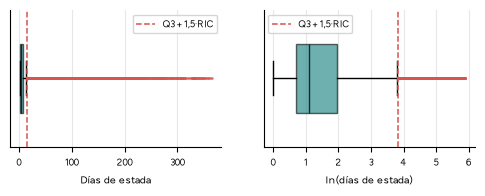

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(6.0, 1.78))
for a, col, titulo in zip(ax, ["dias_estada", "log_dias"], ["Días de estada", "ln(días de estada)"]):
    a.boxplot(df[col], orientation="horizontal", widths=0.5, patch_artist=True,
              boxprops=dict(facecolor=teal, alpha=0.6), medianprops=dict(color=petroleo),
              flierprops=dict(marker=".", markersize=2, markerfacecolor=coral, markeredgecolor=coral, alpha=0.3))
    a.axvline(atip.loc["días" if col == "dias_estada" else "ln(días)", "Ls"], color=coral, linestyle="--", label="Q3 + 1,5·RIC")
    a.set_xlabel(titulo)
    a.set_yticks([])
    a.legend()
plt.show()

En días, la caja está pegada a la izquierda y los puntos rojos llegan hasta 365 días, el máximo que dejamos. En ln(días) la caja es simétrica y los puntos forman una cola más corta. Conservamos los egresos de 15 a 365 días porque las estadías largas forman parte del fenómeno estudiado. Excluimos los de más de 365 días conforme al criterio del Avance 1; el máximo registrado es 16.598 días (unos 45 años). El filtro no demuestra que todos los registros excluidos sean erróneos. Modelamos ln(días), que reduce la influencia de estos valores en los coeficientes, y revisamos sus residuos en 3.6.

### Etapa 5: relación entre variables

Antes de ver si las variables explicativas se repiten entre sí, miramos cómo cambia ln(días) según los tres factores con más diferencia en el Avance 1: capítulo, establecimiento y sexo.

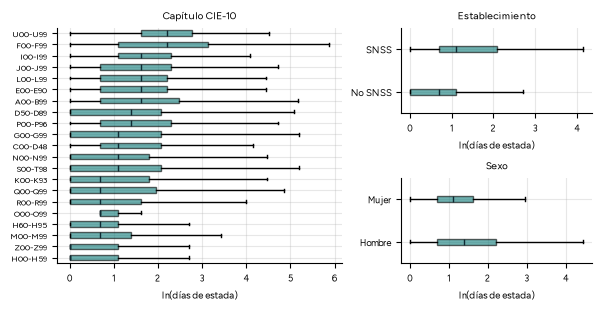

Mediana de días por capítulo: mínima 1.0 (H00-H59), máxima 9.0 (U00-U99)
Mediana de días por establecimiento: {'No SNSS': 2.0, 'SNSS': 3.0}
Mediana de días por sexo: {'HOMBRE': 4.0, 'MUJER': 3.0}
Mediana de días por cirugía: {'No': 4.0, 'Sí': 2.0} | por condición de egreso: {'No': 3.0, 'Sí': 7.0}


In [11]:
fig = figuras.bivariado(df)
figuras.guardar(fig, "avance2_bivariado", png=True)
plt.show()
med = df.groupby("capitulo")["dias_estada"].median().sort_values()
print("Mediana de días por capítulo: mínima", med.iloc[0], "(" + med.index[0] + "), máxima", med.iloc[-1], "(" + med.index[-1] + ")")
print("Mediana de días por establecimiento:", df.groupby("establecimiento")["dias_estada"].median().to_dict())
print("Mediana de días por sexo:", df.groupby("sexo")["dias_estada"].median().to_dict())
print("Mediana de días por cirugía:", df.groupby("cirugia")["dias_estada"].median().to_dict(),
      "| por condición de egreso:", df.groupby("fallecido")["dias_estada"].median().to_dict())

**Figura 3 (informe).** Distribución de ln(días) por capítulo CIE-10 (ordenados por mediana), por tipo de establecimiento y por sexo. Sin puntos atípicos, para ver las cajas. Fuente: DEIS, MINSAL, egresos hospitalarios 2020; elaboración propia.

Las cajas se mueven bastante entre capítulos: la mediana de días va de 1 (H00-H59, ojo) a 9 (U00-U99, uso especial), y la de F00-F99 queda también arriba. Entre establecimientos la diferencia es más corta (mediana de 3 días en el SNSS contra 2 fuera del SNSS), y entre sexos también (4 días en hombres contra 3 en mujeres). Esto anticipa el orden del modelo: el capítulo separa mucho más los egresos que el establecimiento o el sexo. Cirugía y condición de egreso tienen medianas de 2 y 4 días (con y sin cirugía) y de 7 y 3 días (fallecido y vivo), pero la mayor parte de esa diferencia se achica al controlar por el diagnóstico (3.7).

Para ver si las variables explicativas categóricas se repiten entre sí, calculamos la V de Cramér entre todos los pares. La edad queda fuera por ser numérica.

capitulo  cirugia            0.429
          sexo               0.428
cirugia   establecimiento    0.283
capitulo  fallecido          0.261
          establecimiento    0.190
% de egresos con cirugía por capítulo: mínimo 0.7 (F00-F99), máximo 75.0 (M00-M99)
% de mujeres en O00-O99: 100.0


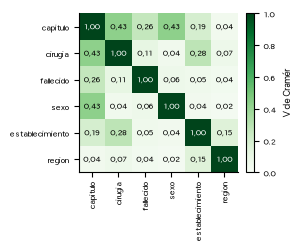

In [12]:
cats = ["capitulo", "cirugia", "fallecido", "sexo", "establecimiento", "region"]
V = pd.DataFrame(1.0, index=cats, columns=cats)
for i, a in enumerate(cats):
    for b in cats[i + 1:]:
        tabla = pd.crosstab(df[a], df[b])
        chi2 = stats.chi2_contingency(tabla)[0]
        V.loc[a, b] = V.loc[b, a] = np.sqrt(chi2 / (len(df) * (min(tabla.shape) - 1)))

pares = V.where(~np.eye(len(cats), dtype=bool)).stack()
pares = pares[[a < b for a, b in pares.index]].sort_values(ascending=False)
print(pares.round(3).head(5).to_string())
cir = 100 * df.groupby("capitulo")["cirugia"].apply(lambda s: (s == "Sí").mean())
print("% de egresos con cirugía por capítulo: mínimo", round(cir.min(), 1), "(" + cir.idxmin() + "), máximo", round(cir.max(), 1), "(" + cir.idxmax() + ")")
print("% de mujeres en O00-O99:", round(100 * (df.loc[df["capitulo"] == "O00-O99", "sexo"] == "MUJER").mean(), 1))

fig = figuras.cramer(V)
figuras.guardar(fig, "avance2_cramer", png=True)
plt.show()

**Figura A1 (informe).** V de Cramér entre las variables explicativas categóricas.

El máximo es 0,43 (capítulo y cirugía), seguido de capítulo y sexo (0,43) y cirugía y establecimiento (0,28). Es una asociación mediana según Cohen (1988) y tiene sentido: la proporción con cirugía va de 0,7 % (F00-F99) a 75,0 % (M00-M99), y O00-O99 es solo de mujeres. No llega a la redundancia de `DIAG2`, y lo confirmamos con el VIF en 3.6. Mantenemos las tres variables.

Trabajamos con todos los egresos de la base analítica. La unidad de análisis es el egreso, no el paciente. No realizamos particiones: buscamos caracterizar las asociaciones en esta población y período.

### Pruebas de asociación de a pares (Avance 1)

Repetimos las 20 pruebas del Avance 1 sobre la misma base, para que la tabla 4 y el anexo A del informe salga de este notebook. Usamos α = 0,05. La normalidad de los días y de la edad se revisa con Shapiro-Wilk (en una muestra de 5.000 egresos, porque con más datos su valor-p deja de ser exacto), Kolmogorov-Smirnov con corrección de Lilliefors y Anderson-Darling. Las asociaciones se miden con Spearman entre dos numéricas, con Mann-Whitney U o Kruskal-Wallis entre una numérica y una categórica, y con chi-cuadrado y V de Cramér entre dos categóricas. En Mann-Whitney el tamaño del efecto es la correlación biserial de rangos r (Kerby, 2014); r > 0 indica estadías más largas en el primer grupo por orden alfabético. En Kruskal-Wallis usamos ε² = H / (n − 1). Los umbrales de Cohen (1988) son 0,1, 0,3 y 0,5 para ρ, r y V, y 0,01, 0,06 y 0,14 para ε².

In [13]:
normalidad = []
for var in ["dias_estada", "edad"]:
    x = df[var].astype(float)
    sw = stats.shapiro(x.sample(5000, random_state=1))
    ks_d, ks_p = lilliefors(x, pvalmethod="approx")
    ad = stats.anderson(x, dist="norm", method="interpolate")   # scipy no informa valores-p menores que 0,01
    normalidad.append({"variable": var, "Shapiro-Wilk W": sw.statistic, "p SW": sw.pvalue,
                       "Lilliefors D": ks_d, "p KS": ks_p, "Anderson-Darling A²": ad.statistic, "p AD": ad.pvalue})
normalidad = pd.DataFrame(normalidad).set_index("variable")
normalidad.round(3)

,Shapiro-Wilk W,p SW,Lilliefors D,p KS,Anderson-Darling A²,p AD
variable,,,,,,
dias_estada,0.442,0.0,0.328,0.0,150920.967,0.01
edad,0.957,0.0,0.129,0.0,13546.111,0.01


In [14]:
pruebas = []
rho, p = stats.spearmanr(df["edad"], df["dias_estada"])
pruebas.append({"variable": "edad", "respuesta": "días", "prueba": "Spearman", "estadístico": rho, "valor-p": p,
                "medida": "ρ", "efecto": rho, "detalle": ""})
for var in ["sexo", "nacionalidad", "etnia", "cirugia", "fallecido", "establecimiento"]:
    g1, g2 = sorted(df[var].unique())
    x1, x2 = df.loc[df[var] == g1, "dias_estada"], df.loc[df[var] == g2, "dias_estada"]
    u, p = stats.mannwhitneyu(x1, x2)
    pruebas.append({"variable": var, "respuesta": "días", "prueba": "Mann-Whitney U", "estadístico": u, "valor-p": p,
                    "medida": "r", "efecto": 2 * u / (len(x1) * len(x2)) - 1,
                    "detalle": f"{g1} / {g2}: medianas {x1.median():.0f} / {x2.median():.0f}"})
for var in ["capitulo", "region"]:
    h_kw, p = stats.kruskal(*[g["dias_estada"] for _, g in df.groupby(var)])
    med_kw = df.groupby(var)["dias_estada"].median()
    pruebas.append({"variable": var, "respuesta": "días", "prueba": "Kruskal-Wallis", "estadístico": h_kw, "valor-p": p,
                    "medida": "ε²", "efecto": h_kw / (len(df) - 1),
                    "detalle": f"medianas de {med_kw.min():.0f} ({med_kw.idxmin()}) a {med_kw.max():.0f} ({med_kw.idxmax()}) días"})
mediana_tramo = df.groupby("tramo_edad")["dias_estada"].median()
print("Mediana de días por tramo de edad:", mediana_tramo.to_dict())
pd.DataFrame(pruebas)[["variable", "prueba", "valor-p", "medida", "efecto", "detalle"]].round(3)

Mediana de días por tramo de edad: {'1 a 9': 2.0, '10 a 19': 2.0, '20 a 29': 2.0, '30 a 39': 2.0, '40 a 49': 3.0, '50 a 59': 4.0, '60 a 69': 5.0, '70 a 79': 5.0, '80 a 89': 6.0, '90 y más': 6.0, 'menor de un año': 4.0}


,variable,prueba,valor-p,medida,efecto,detalle
0,edad,Spearman,0.0,ρ,0.250,
1,sexo,Mann-Whitney U,0.0,r,0.140,HOMBRE / MUJER: medianas 4 / 3
2,nacionalidad,Mann-Whitney U,0.0,r,0.062,Chileno / extranjero: medianas 3 / 3
3,etnia,Mann-Whitney U,0.0,r,-0.025,No / Sí: medianas 3 / 3
4,cirugia,Mann-Whitney U,0.0,r,0.224,No / Sí: medianas 4 / 2
5,fallecido,Mann-Whitney U,0.0,r,-0.292,No / Sí: medianas 3 / 7
6,establecimiento,Mann-Whitney U,0.0,r,-0.374,No SNSS / SNSS: medianas 2 / 3
7,capitulo,Kruskal-Wallis,0.0,ε²,0.120,medianas de 1 (H00-H59) a 9 (F00-F99) días
8,region,Kruskal-Wallis,0.0,ε²,0.002,medianas de 2 (De Aisén del Gral. C. Ibáñez de...


In [15]:
posthoc = {}
for var in ["capitulo", "region"]:
    niveles = sorted(df[var].unique())
    grupos = {n: df.loc[df[var] == n, "dias_estada"].values for n in niveles}
    valores_p = [stats.mannwhitneyu(grupos[a], grupos[b]).pvalue for i, a in enumerate(niveles) for b in niveles[i + 1:]]
    rechaza = multipletests(valores_p, method="holm")[0]
    posthoc[var] = {"pares": len(valores_p), "distintos": int(rechaza.sum())}
    print(f"{var}: {rechaza.sum()} de {len(valores_p)} pares son distintos (Holm, α = 0,05)")

capitulo: 202 de 210 pares son distintos (Holm, α = 0,05)


region: 104 de 120 pares son distintos (Holm, α = 0,05)


In [16]:
pct_prolongadas_grupo = {}
for var in ["tramo_edad", "sexo", "nacionalidad", "etnia", "capitulo", "cirugia", "fallecido", "establecimiento", "region"]:
    tabla = pd.crosstab(df[var], df["prolongada"])
    chi2, p, gl, esperadas = stats.chi2_contingency(tabla)
    pct = 100 * tabla["Sí"] / tabla.sum(axis=1)
    pct_prolongadas_grupo[var] = pct
    pruebas.append({"variable": var, "respuesta": "prolongada", "prueba": "Chi-cuadrado", "estadístico": chi2, "gl": gl,
                    "valor-p": p, "medida": "V", "efecto": np.sqrt(chi2 / (len(df) * (min(tabla.shape) - 1))),
                    "detalle": f"% prolongadas de {pct.min():.1f} ({pct.idxmin()}) a {pct.max():.1f} ({pct.idxmax()})",
                    "esperada mínima": esperadas.min()})
pruebas_pares = pd.DataFrame(pruebas)
ef = pruebas_pares.set_index(["variable", "respuesta"])["efecto"]
n_pruebas = len(normalidad) + len(pruebas_pares)
print("Pruebas de a pares:", n_pruebas, "| mayor valor-p de asociación:", pruebas_pares["valor-p"].max(),
      "| menor frecuencia esperada:", round(pruebas_pares["esperada mínima"].min()))
for var in ["tramo_edad", "fallecido", "sexo", "establecimiento"]:
    print(var, pct_prolongadas_grupo[var].round(1).to_dict())
pruebas_pares.loc[pruebas_pares["prueba"] == "Chi-cuadrado", ["variable", "estadístico", "gl", "valor-p", "efecto", "detalle", "esperada mínima"]].round(3)

Pruebas de a pares: 20 | mayor valor-p de asociación: 0.00019322785870775011 | menor frecuencia esperada: 175
tramo_edad {'1 a 9': 4.3, '10 a 19': 6.7, '20 a 29': 3.5, '30 a 39': 4.2, '40 a 49': 8.2, '50 a 59': 12.1, '60 a 69': 14.4, '70 a 79': 15.4, '80 a 89': 14.7, '90 y más': 11.7, 'menor de un año': 15.4}
fallecido {'No': 8.8, 'Sí': 25.3}
sexo {'HOMBRE': 13.1, 'MUJER': 6.9}
establecimiento {'No SNSS': 4.2, 'SNSS': 10.6}


,variable,estadístico,gl,valor-p,efecto,detalle,esperada mínima
9,tramo_edad,26265.083,10.0,0.0,0.165,% prolongadas de 3.5 (20 a 29) a 15.4 (menor d...,1408.383
10,sexo,10332.249,1.0,0.0,0.103,% prolongadas de 6.9 (MUJER) a 13.1 (HOMBRE),36375.695
11,nacionalidad,641.894,1.0,0.0,0.026,% prolongadas de 5.7 (extranjero) a 9.5 (Chileno),3599.463
12,etnia,13.896,1.0,0.0,0.004,% prolongadas de 8.6 (Sí) a 9.4 (No),1986.931
13,capitulo,60840.389,20.0,0.0,0.251,% prolongadas de 0.9 (O00-O99) a 35.6 (F00-F99),174.757
14,cirugia,2749.328,1.0,0.0,0.053,% prolongadas de 7.4 (Sí) a 10.6 (No),34007.417
15,fallecido,11514.501,1.0,0.0,0.109,% prolongadas de 8.8 (No) a 25.3 (Sí),3506.122
16,establecimiento,6896.670,1.0,0.0,0.084,% prolongadas de 4.2 (No SNSS) a 10.6 (SNSS),16504.041
17,region,2343.468,15.0,0.0,0.049,% prolongadas de 6.6 (De Aisén del Gral. C. Ib...,673.954


### Gráficos y tablas de contingencia de las pruebas de a pares (anexo A del informe)

La pauta del Avance 1 pide acompañar cada prueba con su gráfico: histograma y Q-Q para la normalidad, dispersión para Spearman, boxplots por grupo para Mann-Whitney y Kruskal-Wallis, y tabla de contingencia con barras apiladas para el chi-cuadrado. Como la edad viene en tramos de 10 años, un gráfico de dispersión mostraría solo 11 columnas de puntos; en su lugar mostramos ln(días) por tramo de edad. Los Q-Q usan la misma muestra de 5.000 egresos de Shapiro-Wilk. Son las figuras A2 a A4 y la tabla A2 del informe. El código de todas las figuras está en `paper/figuras.py`.

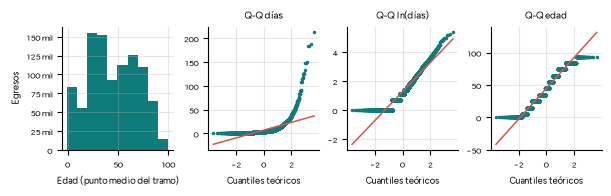

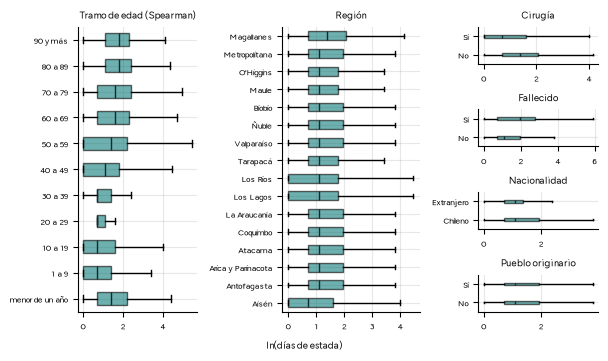

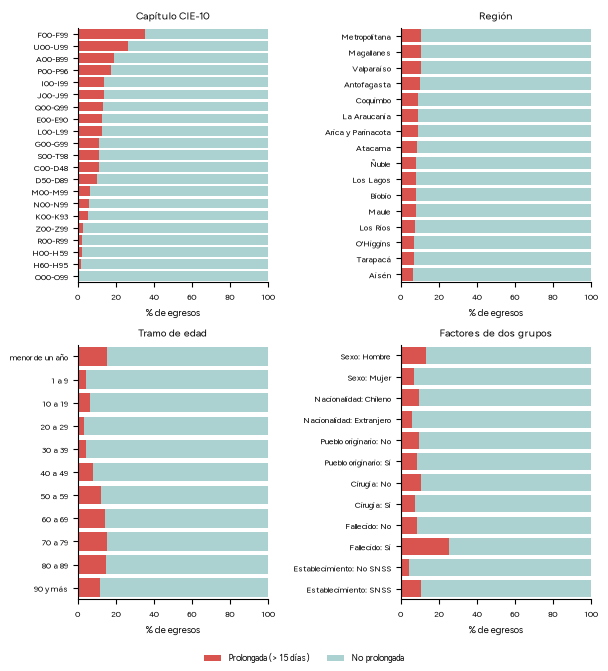

{'tramo_edad': 968098, 'sexo': 968098, 'nacionalidad': 968098, 'etnia': 968098, 'capitulo': 968098, 'cirugia': 968098, 'fallecido': 968098, 'establecimiento': 968098, 'region': 968098}


In [17]:
# Normalidad (histograma y Q-Q), boxplots de los demás factores y barras apiladas del chi-cuadrado
for fig, nombre in [(figuras.normalidad(df), "anexo_normalidad"), (figuras.cajas(df), "anexo_cajas"),
                    (figuras.prolongadas(pct_prolongadas_grupo), "anexo_prolongadas")]:
    figuras.guardar(fig, nombre)
    plt.show()

# Tablas de contingencia de los chi-cuadrado (anexo A del informe, las escribe paper/gen_anexos.py)
contingencia = {var: pd.crosstab(df[var], df["prolongada"]) for var in pct_prolongadas_grupo}
print({k: int(v.values.sum()) for k, v in contingencia.items()})


In [18]:
def magnitud(medida, x):
    a, (c1, c2, c3) = abs(x), ((0.01, 0.06, 0.14) if medida == "ε²" else (0.1, 0.3, 0.5))
    return "grande" if a >= c3 else "mediano" if a >= c2 else "pequeño" if a >= c1 else "despreciable"
decimales = {"ρ": 2, "r": 2, "V": 2, "ε²": 2}
filas = [{"variable 1": "días y edad", "variable 2": "normalidad", "prueba": "Shapiro-Wilk, Lilliefors, Anderson-Darling",
          "efecto": "", "magnitud": "",
          "valor-p": f"SW y KS < 0,001; AD = {es(normalidad['p AD'].max(), 2)}"}]
for _, f in pruebas_pares.iterrows():
    d = 3 if abs(f["efecto"]) < 0.01 else decimales[f["medida"]]
    filas.append({"variable 1": f["variable"], "variable 2": f["respuesta"], "prueba": f["prueba"],
                  "efecto": f"{f['medida']} = {es(f['efecto'], d)}", "magnitud": magnitud(f["medida"], f["efecto"]),
                  "valor-p": "< 0,001" if f["valor-p"] < 0.001 else es(f["valor-p"], 4)})
resumen_pares = pd.DataFrame(filas)
resumen_pares

,variable 1,variable 2,prueba,efecto,magnitud,valor-p
0,días y edad,normalidad,"Shapiro-Wilk, Lilliefors, Anderson-Darling",,,"SW y KS < 0,001; AD = 0,01"
1,edad,días,Spearman,"ρ = 0,25",pequeño,"< 0,001"
2,sexo,días,Mann-Whitney U,"r = 0,14",pequeño,"< 0,001"
3,nacionalidad,días,Mann-Whitney U,"r = 0,06",despreciable,"< 0,001"
4,etnia,días,Mann-Whitney U,"r = −0,02",despreciable,"< 0,001"
5,cirugia,días,Mann-Whitney U,"r = 0,22",pequeño,"< 0,001"
6,fallecido,días,Mann-Whitney U,"r = −0,29",pequeño,"< 0,001"
7,establecimiento,días,Mann-Whitney U,"r = −0,37",mediano,"< 0,001"
8,capitulo,días,Kruskal-Wallis,"ε² = 0,12",mediano,"< 0,001"
9,region,días,Kruskal-Wallis,"ε² = 0,002",despreciable,"< 0,001"


Las tres pruebas rechazan la normalidad de los días y de la edad (Shapiro-Wilk y Lilliefors con p < 0,001; Anderson-Darling con p ≤ 0,01, porque scipy no informa valores menores), por eso usamos pruebas no paramétricas. La edad se relaciona con los días con ρ = 0,25: a mayor edad la estadía tiende a ser más larga, con un efecto pequeño. La mediana sube de 2 días entre los 20 y 29 años a 6 días desde los 80, con la excepción de los menores de un año (4 días). Con Mann-Whitney y Kruskal-Wallis todos los factores rechazan H₀ (p < 0,001), con efectos distintos: establecimiento (r = −0,37) y capítulo (ε² = 0,12) son medianos; condición de egreso, cirugía y sexo son pequeños; nacionalidad, etnia y región son despreciables. En el chi-cuadrado todas las frecuencias esperadas superan 5 (la menor es 175). La asociación más fuerte con la estadía prolongada es la del capítulo (V = 0,25), que va de 0,9 % de prolongadas en O00-O99 a 35,6 % en F00-F99. La edad tiene forma de U: 15,4 % en menores de un año, 3,5 % entre 20 y 29 años y 15,4 % entre 70 y 79. Con casi un millón de egresos hasta una V de 0,004 (etnia) sale significativa, así que estas pruebas no sirven para elegir las variables del modelo. Las 18 pruebas de asociación tienen p < 0,0002, de modo que la corrección de Bonferroni (0,05 / 20 = 0,0025) no cambia ninguna decisión.

**Tabla complementaria.** Caracterización de la base analítica completa.

In [19]:
base_analitica = pd.DataFrame({
    "egresos": [len(df)], "media de días": [df["dias_estada"].mean()],
    "mediana de días": [df["dias_estada"].median()],
    "% prolongadas": [100 * (df["prolongada"] == "Sí").mean()],
    "% SNSS": [100 * (df["establecimiento"] == "SNSS").mean()],
    "% fallecidos": [100 * (df["fallecido"] == "Sí").mean()],
    "edad media": [df["edad"].mean()]}, index=["base completa"])
assert len(df) == 968098
base_analitica.round(2)

,egresos,media de días,mediana de días,% prolongadas,% SNSS,% fallecidos,edad media
base completa,968098,6.7,3.0,9.39,81.85,3.86,45.01


## 3. Resultados y modelamiento

### 3.1 Modelo propuesto en el Avance 1

Estimamos por mínimos cuadrados ordinarios un modelo de ln(días) con capítulo CIE-10, cirugía, condición de egreso, edad centrada y su cuadrado, sexo, establecimiento y región. Los siete factores se incluyen simultáneamente para describir la asociación de cada uno manteniendo constantes los demás.

$$\ln(\text{días}_i)=\beta_0+\sum_c\gamma_c\text{capítulo}_{ic}+\beta_1\text{cirugía}_i+\beta_2\text{fallecido}_i+\beta_3\text{edad}_{c,i}+\beta_4\text{edad}_{c,i}^2+\beta_5\text{hombre}_i+\beta_6\text{SNSS}_i+\sum_r\delta_r\text{región}_{ir}+\varepsilon_i$$

El modelo representa la media condicional de ln(días). Su exponencial corresponde a una media geométrica condicional; solo coincide con la mediana condicional si el error en escala logarítmica tiene mediana cero. Interpretamos 100·(exp(β)−1) como cambio porcentual en la media geométrica, sin equipararlo automáticamente a cambios en la media aritmética o la mediana. En la edad, el cambio depende del término lineal y del cuadrático.

### 3.2 Modelos anidados

M0 incluye el intercepto; M1 añade el bloque clínico; M2 añade edad, edad² y sexo; M3 añade establecimiento y región. Todos usan los mismos egresos. F parcial, BIC y η² parcial permiten comparar el aporte de los bloques, bajo los supuestos respectivos. La contribución secuencial depende del orden de entrada; por eso también retiramos cada factor de M3 para medir su aporte ajustado.

**Tabla 5 (informe).** Modelos anidados M0 a M3 en la base completa. Fuente: DEIS, MINSAL, egresos hospitalarios 2020; elaboración propia.

In [20]:
cap = "C(capitulo, Treatment('K00-K93'))"
reg = "C(region, Treatment('Metropolitana de Santiago'))"
f1 = f"log_dias ~ {cap} + C(cirugia) + C(fallecido)"
f2 = f1 + " + edad_c + I(edad_c**2) + C(sexo, Treatment('MUJER'))"
f3 = f2 + f" + C(establecimiento) + {reg}"
modelos = [smf.ols(f, df).fit() for f in ["log_dias ~ 1", f1, f2, f3]]
m3 = modelos[3]

filas = []
for i, m in enumerate(modelos):
    fila = {"modelo": f"M{i}", "k": int(m.df_model) + 1, "R²": m.rsquared, "R² aj.": m.rsquared_adj, "BIC": m.bic}
    if i > 0:
        fila["η² parcial"] = (m.rsquared - modelos[i - 1].rsquared) / (1 - modelos[i - 1].rsquared)   # η² parcial = SC del bloque / (SC del bloque + SC del error)
        a = anova_lm(modelos[i - 1], m)
        fila.update({"Δ BIC": m.bic - modelos[i - 1].bic, "F parcial": a["F"].iloc[1],
                     "gl": int(a["df_diff"].iloc[1]), "valor-p": a["Pr(>F)"].iloc[1]})
    filas.append(fila)
tabla_modelos = pd.DataFrame(filas).set_index("modelo")
tabla_modelos["BIC"] = tabla_modelos["BIC"].round(0)
tabla_modelos["Δ BIC"] = tabla_modelos["Δ BIC"].round(0)
tabla_modelos.round(4) + 0

,k,R²,R² aj.,BIC,η² parcial,Δ BIC,F parcial,gl,valor-p
modelo,,,,,,,,,
M0,1,0.0000,0.0000,2814166.0,NaN,NaN,NaN,NaN,NaN
M1,23,0.1324,0.1324,2676930.0,0.1324,-137235.0,6717.4806,22.0,0.0
M2,26,0.1618,0.1618,2643664.0,0.0338,-33266.0,11295.4580,3.0,0.0
M3,42,0.1980,0.1980,2601099.0,0.0432,-42565.0,2733.9366,16.0,0.0


La tabla anterior muestra cuánto cambia el ajuste al incorporar cada bloque. El R² expresa la fracción de variación de ln(días) explicada en la base completa. Un BIC menor favorece el equilibrio entre ajuste y complejidad dentro de estos modelos y no prueba causalidad.

**Resultados.** El R² ajustado pasa por M1: 0,132, M2: 0,162, M3: 0,198. M3 deja sin explicar aproximadamente el 80,2 % de la variación de ln(días).


**Tabla complementaria.** η² de cada bloque (primera salida). **Tabla 7 (informe, ranking).** η² parcial de cada factor (segunda salida). Fuente: DEIS, MINSAL, egresos hospitalarios 2020; elaboración propia.

In [21]:
def cohen(e2):                                    # umbrales de Cohen (1988) para η², los mismos que usamos con ε² en el Avance 1
    return "grande" if e2 >= 0.14 else "mediano" if e2 >= 0.06 else "pequeño" if e2 >= 0.01 else "menor que pequeño"

r2_3 = m3.rsquared
bloques = pd.DataFrame({"comparación": ["M1 frente a M0 (clínico)", "M2 frente a M1 (edad y sexo)", "M3 frente a M2 (establecimiento y región)", "M3 frente a M0 (modelo completo)"],
                        "η²": [(modelos[j].rsquared - modelos[k0].rsquared) / (1 - modelos[k0].rsquared) for j, k0 in [(1, 0), (2, 1), (3, 2), (3, 0)]]})
bloques["efecto (Cohen)"] = bloques["η²"].map(cohen)

# η² parcial de cada factor: lo quitamos de M3 (ajuste OLS en la base completa) y vemos cuánto baja el R²
terminos = {"capítulo": cap, "cirugía": "C(cirugia)", "fallecido": "C(fallecido)", "edad (edad y edad²)": "edad_c + I(edad_c**2)",
            "sexo": "C(sexo, Treatment('MUJER'))", "establecimiento": "C(establecimiento)", "región": reg}
filas = []
for nombre in terminos:
    sin = smf.ols("log_dias ~ " + " + ".join(t for n, t in terminos.items() if n != nombre), df).fit()
    filas.append({"factor": nombre, "R² sin el factor": sin.rsquared, "η² parcial": (r2_3 - sin.rsquared) / (1 - sin.rsquared)})
parciales = pd.DataFrame(filas).set_index("factor")
parciales["efecto (Cohen)"] = parciales["η² parcial"].map(cohen)
print("R² de M3:", round(r2_3, 4))
print(bloques.round(4).to_string(index=False), "\n")
print(parciales.sort_values("η² parcial", ascending=False).round(4).to_string())

R² de M3: 0.198
                              comparación     η² efecto (Cohen)
                 M1 frente a M0 (clínico) 0.1324        mediano
             M2 frente a M1 (edad y sexo) 0.0338        pequeño
M3 frente a M2 (establecimiento y región) 0.0432        pequeño
         M3 frente a M0 (modelo completo) 0.1980         grande 

                     R² sin el factor  η² parcial     efecto (Cohen)
factor                                                              
capítulo                       0.1339      0.0740            mediano
establecimiento                0.1638      0.0409            pequeño
edad (edad y edad²)            0.1692      0.0347            pequeño
región                         0.1942      0.0048  menor que pequeño
sexo                           0.1959      0.0026  menor que pequeño
cirugía                        0.1979      0.0002  menor que pequeño
fallecido                      0.1979      0.0001  menor que pequeño


**Relevancia de bloques y factores.** Con una base tan grande, diferencias pequeñas pueden resultar significativas. Usamos η² parcial = (R² completo − R² reducido) / (1 − R² reducido), con umbrales orientativos de 0,01, 0,06 y 0,14. La tabla distingue el aporte secuencial de cada bloque y el aporte de cada factor al retirarlo del modelo completo. Estos aportes no son aditivos y no atribuyen al factor toda la variación compartida con otros.

La ANOVA siguiente descompone la variación total de ln(días).

**Orden de aporte ajustado:** capítulo: η² parcial = 0,0740 (mediano); establecimiento: η² parcial = 0,0409 (pequeño); edad (edad y edad²): η² parcial = 0,0347 (pequeño); región: η² parcial = 0,0048 (menor que pequeño); sexo: η² parcial = 0,0026 (menor que pequeño); cirugía: η² parcial = 0,0002 (menor que pequeño); fallecido: η² parcial = 0,0001 (menor que pequeño).


**Tabla complementaria.** Tabla ANOVA del modelo completo M3. Fuente: DEIS, MINSAL, egresos hospitalarios 2020; elaboración propia.

In [22]:
anova = pd.DataFrame({
    "Suma de cuadrados (SS)": [m3.ess, m3.ssr, m3.centered_tss],
    "Grados de libertad (gl)": [m3.df_model, m3.df_resid, m3.nobs - 1],
    "Cuadrado medio (MS)": [m3.mse_model, m3.mse_resid, np.nan],
    "F": [m3.fvalue, np.nan, np.nan],
    "valor-p": [m3.f_pvalue, np.nan, np.nan]},
    index=["Regresión", "Residual", "Total"])
anova.index.name = "Fuente de variación"
anova.round(3)

,Suma de cuadrados (SS),Grados de libertad (gl),Cuadrado medio (MS),F,valor-p
Fuente de variación,,,,,
Regresión,205399.101,41.0,5009.734,5829.904,0.0
Residual,831866.727,968056.0,0.859,NaN,NaN
Total,1037265.829,968097.0,NaN,NaN,NaN


La ANOVA contrasta la hipótesis conjunta de coeficientes de pendiente nulos. Se interpreta junto con R² y η² parcial: un valor-p pequeño no implica por sí solo una asociación sustantivamente grande.

### 3.3 Coeficientes de M3

Presentamos estimaciones e intervalos de confianza del 95 %. Junto al error estándar clásico mostramos el error estándar robusto a heterocedasticidad HC3, porque en 3.6 la dispersión de los residuos crece con el valor ajustado. HC3 cambia los errores estándar y deja iguales los coeficientes. Ninguna de las dos versiones permite leer las asociaciones como efectos causales.

En la base completa, F global = 5.829,9, con 41 y 968056 grados de libertad (p < 0,001). El rechazo de la hipótesis conjunta indica asociación en al menos un coeficiente bajo el contraste clásico; no implica que todos los factores sean relevantes.


**Tabla 6 (informe).** Coeficientes de M3 con error estándar clásico (EE) y robusto a heterocedasticidad (HC3). %Δ = 100·(exp(β) − 1), con intervalo de confianza del 95 % clásico. La primera salida tiene las filas del informe, la segunda la fila de la edad con seis decimales y la tercera la tabla ampliada.

In [23]:
# Errores estándar HC3: (X'X)⁻¹ X' diag(e² / (1 − h)²) X (X'X)⁻¹, con h la diagonal de la matriz sombrero.
# Los coeficientes son los mismos de M3; solo cambian los errores estándar.
X_h, e_h = m3.model.exog, m3.resid.values
XtXi = np.linalg.inv(X_h.T @ X_h)
h_diag = np.einsum("ij,jk,ik->i", X_h, XtXi, X_h)
carne = (X_h * ((e_h / (1 - h_diag)) ** 2)[:, None]).T @ X_h
ee_hc3 = np.sqrt(np.diag(XtXi @ carne @ XtXi))
ic = m3.conf_int()
coef = pd.DataFrame({"β": m3.params, "EE": m3.bse, "EE HC3": ee_hc3, "t": m3.tvalues, "valor-p": m3.pvalues,
                     "valor-p HC3": 2 * stats.norm.sf(np.abs(m3.params.values / ee_hc3)),
                     "IC inf": ic[0], "IC sup": ic[1],
                     "IC HC3 inf": m3.params.values - 1.96 * ee_hc3, "IC HC3 sup": m3.params.values + 1.96 * ee_hc3})
coef["EE HC3 / EE"] = coef["EE HC3"] / coef["EE"]
for col, base in [("%Δ", "β"), ("%Δ inf", "IC inf"), ("%Δ sup", "IC sup"), ("%Δ HC3 inf", "IC HC3 inf"), ("%Δ HC3 sup", "IC HC3 sup")]:
    coef[col] = 100 * (np.exp(coef[base]) - 1)
coef.index = coef.index.str.replace(r"C\((\w+)[^\[]*\[T\.(.*)\]", r"\1: \2", regex=True)
hc3_resumen = {"razon_min": coef["EE HC3 / EE"].min(), "razon_max": coef["EE HC3 / EE"].max(),
               "coef_razon_min": coef["EE HC3 / EE"].idxmin(), "coef_razon_max": coef["EE HC3 / EE"].idxmax(),
               "cambios_significancia": int(((coef["valor-p"] < 0.05) != (coef["valor-p HC3"] < 0.05)).sum())}

en_cap = coef.index[coef.index.str.startswith("capitulo")]
destacados = list(coef.loc[en_cap, "β"].nlargest(4).index) + list(coef.loc[en_cap, "β"].nsmallest(2).index)
otros = ["cirugia: Sí", "fallecido: Sí", "sexo: HOMBRE", "establecimiento: SNSS", "edad_c", "I(edad_c ** 2)"]
cols_paper = ["β", "EE", "EE HC3", "%Δ", "%Δ inf", "%Δ sup"]
print("Coeficientes:", len(coef), "| máximo |β| entre regiones:", round(coef.filter(like="region", axis=0)["β"].abs().max(), 3))
print("EE HC3 / EE clásico: de", round(hc3_resumen["razon_min"], 2), "a", round(hc3_resumen["razon_max"], 2),
      "| coeficientes que cambian de significación con HC3:", hc3_resumen["cambios_significancia"])
print("F00-F99, IC 95 % del %Δ: clásico", coef.loc["capitulo: F00-F99", ["%Δ inf", "%Δ sup"]].round(1).tolist(),
      "| HC3", coef.loc["capitulo: F00-F99", ["%Δ HC3 inf", "%Δ HC3 sup"]].round(1).tolist())
print(coef.loc[destacados + otros[:4], cols_paper].round({"β": 3, "EE": 3, "EE HC3": 3, "%Δ": 1, "%Δ inf": 1, "%Δ sup": 1}).to_string(), "\n")
print(coef.loc[["edad_c"], cols_paper].round({"β": 3, "EE": 6, "EE HC3": 6, "%Δ": 2, "%Δ inf": 2, "%Δ sup": 2}).to_string(), "\n")
coef.loc[["Intercept"] + destacados + otros, cols_paper + ["t", "valor-p", "valor-p HC3"]].round(3)
del carne, h_diag


Coeficientes: 42 | máximo |β| entre regiones: 0.353
EE HC3 / EE clásico: de 0.8 a 1.36 | coeficientes que cambian de significación con HC3: 0
F00-F99, IC 95 % del %Δ: clásico [210.4, 219.3] | HC3 [208.8, 220.9]
                           β     EE  EE HC3     %Δ  %Δ inf  %Δ sup
capitulo: F00-F99      1.147  0.007   0.010  214.8   210.4   219.3
capitulo: U00-U99      0.880  0.005   0.006  141.2   138.6   143.8
capitulo: P00-P96      0.805  0.007   0.009  123.8   120.5   127.1
capitulo: A00-B99      0.643  0.007   0.009   90.3    87.5    93.0
capitulo: H00-H59     -0.385  0.014   0.012  -31.9   -33.7   -30.1
capitulo: Z00-Z99     -0.356  0.007   0.007  -29.9   -30.9   -28.9
cirugia: Sí           -0.028  0.002   0.002   -2.8    -3.2    -2.3
fallecido: Sí          0.061  0.005   0.007    6.3     5.2     7.3
sexo: HOMBRE           0.107  0.002   0.002   11.3    10.9    11.8
establecimiento: SNSS  0.530  0.003   0.002   70.0    69.1    70.8 

            β        EE   EE HC3    %Δ  %Δ inf  %Δ

La tabla expresa las asociaciones ajustadas respecto de las categorías de referencia. El intercepto exponenciado corresponde a la media geométrica ajustada para una mujer de edad media, viva al egreso, sin cirugía, con diagnóstico digestivo, en un establecimiento no SNSS y de la Región Metropolitana.

Los cambios porcentuales comparan grupos manteniendo constantes los demás factores. La magnitud se interpreta junto con η² parcial. Para edad, β₁ por sí solo describe la pendiente local en la edad de centrado; el cambio de una edad a otra requiere incluir también β₂. Capítulo y región se contrastan como conjuntos mediante F parcial (ANOVA tipo II).

**Asociaciones en media geométrica:**

- SNSS frente a no SNSS: 70,0 % (IC 95 %: 69,1 a 70,8).
- Hombres frente a mujeres: 11,3 % (IC 95 %: 10,9 a 11,8).
- Con cirugía frente a sin cirugía: -2,8 % (IC 95 %: -3,2 a -2,3).
- Fallecidos frente a vivos al egreso: 6,3 % (IC 95 %: 5,2 a 7,3).

Entre capítulos, F00-F99 presenta el mayor cambio (214,8 %) y H00-H59 el menor (-31,9 %) frente a K00-K93. El capítulo es también el factor con mayor η² parcial: la magnitud entre categorías y el aporte global coinciden en señalar su relevancia.


**Tabla complementaria.** Prueba F de cada factor (ANOVA tipo II). Fuente: DEIS, MINSAL, egresos hospitalarios 2020; elaboración propia.

In [24]:
ft = anova_lm(m3, typ=2)                                # F parcial de cada factor (ANOVA tipo II)
ftest = ft.loc[ft.index.str.startswith("C(")].rename(columns={"df": "gl", "PR(>F)": "valor-p"})[["gl", "F", "valor-p"]]
ftest.index = ftest.index.str.replace(r"C\((\w+).*", r"\1", regex=True)
print("Intercepto = ln(días) del paciente de referencia; exp(intercepto) =", round(np.exp(coef.loc["Intercept", "β"]), 2), "días")
en_reg = coef.index[coef.index.str.startswith("region")]
pr = coef.loc[en_reg, "%Δ"].sort_values()
print("Regiones, %Δ vs. Santiago: mínimo", round(pr.iloc[0], 1), "(" + pr.index[0] + "); sin esa, mínimo", round(pr.iloc[1], 1), "| máximo", round(pr.iloc[-1], 1))
print("Sexo (hombre vs. mujer): %Δ =", round(coef.loc["sexo: HOMBRE", "%Δ"], 1), "| IC 95 %:", round(coef.loc["sexo: HOMBRE", "%Δ inf"], 1), "a", round(coef.loc["sexo: HOMBRE", "%Δ sup"], 1))
print("Edad: %Δ por año =", round(coef.loc["edad_c", "%Δ"], 2), "| IC 95 %:", round(coef.loc["edad_c", "%Δ inf"], 2), "a", round(coef.loc["edad_c", "%Δ sup"], 2))
ftest.round(3)

Intercepto = ln(días) del paciente de referencia; exp(intercepto) = 1.82 días
Regiones, %Δ vs. Santiago: mínimo -29.8 (region: De Aisén del Gral. C. Ibáñez del Campo); sin esa, mínimo -15.8 | máximo 0.3
Sexo (hombre vs. mujer): %Δ = 11.3 | IC 95 %: 10.9 a 11.8
Edad: %Δ por año = 0.89 | IC 95 %: 0.88 a 0.9


,gl,F,valor-p
capitulo,20.0,3867.189,0.0
cirugia,1.0,156.954,0.0
fallecido,1.0,138.698,0.0
sexo,1.0,2533.137,0.0
establecimiento,1.0,41286.797,0.0
region,15.0,310.098,0.0


Los contrastes por factor evalúan su aporte condicionado a los demás. La figura siguiente muestra la dirección y magnitud de las asociaciones y sus intervalos; el tamaño de la base explica parte de la estrechez de estos últimos.

**Figura B1 (informe).** Cambio porcentual en la media geométrica ajustada de días de cada coeficiente de M3, con IC del 95 %.

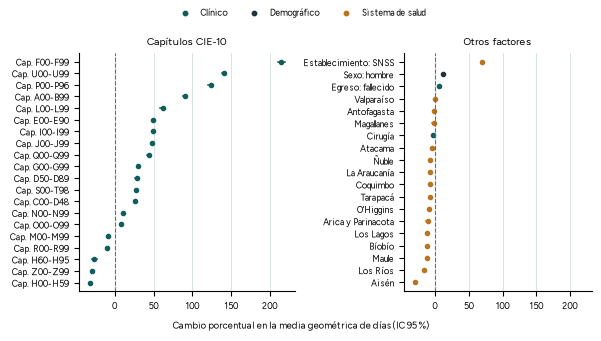

In [25]:
# Figura del cambio porcentual de cada coeficiente (forest), con los coeficientes de arriba
fig = figuras.forest(coef)
figuras.guardar(fig, "forest", png=True)
plt.show()


El orden de relevancia se obtiene de η² parcial, y la dirección de las asociaciones se lee en los coeficientes. No deben confundirse un cambio porcentual grande entre dos categorías y la proporción de variabilidad atribuible al factor completo.

**Figura C2 (informe).** Media observada de ln(días) por tramo de edad y media ajustada por M3 en la base completa.

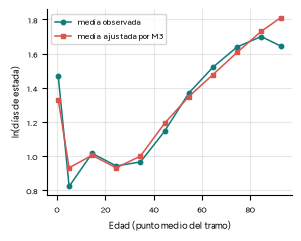

edad       0.5   5.0   14.5  24.5  34.5  44.5  54.5  64.5  74.5  84.5  92.5
log_dias   1.47  0.82  1.02  0.94  0.97  1.15  1.37  1.52  1.64  1.70  1.64
ajuste_ln  1.33  0.93  1.00  0.93  1.00  1.19  1.35  1.48  1.61  1.73  1.81


In [26]:
df["ajuste_ln"] = m3.fittedvalues
por_tramo = df.groupby("edad")[["log_dias", "ajuste_ln"]].mean()
fig = figuras.edad(por_tramo)
figuras.guardar(fig, "avance2_edad", png=True)
plt.show()
print(por_tramo.round(2).T.to_string())

La comparación por edades permite detectar diferencias sistemáticas entre la forma cuadrática y los promedios observados. Son promedios por grupo que también reflejan su composición diagnóstica; no describen por sí solos un efecto causal de la edad. En 3.8 examinamos una especificación por tramos.

### 3.4 Ajuste global

El R² y el R² ajustado de M3 resumen qué parte de la variación de ln(días) se asocia con los siete factores en esta misma base.

En la base completa, para menores de un año la media observada de ln(días) es 1,47 y la ajustada 1,33; entre 1 y 9 años son 0,82 y 0,93. En el tramo de 90 años y más, la media observada es 1,64 y la ajustada 1,81. Estas desviaciones en los extremos motivan evaluar edad por tramos en 3.8.


In [27]:
df["ajuste_ln"] = m3.fittedvalues
df["ajustado_dias"] = np.exp(df["ajuste_ln"])          # se usa en la tabla por deciles
print("R²:", round(m3.rsquared, 3), "| R² ajustado:", round(m3.rsquared_adj, 3),
      "| variación de ln(días) sin explicar:", round(100 * (1 - m3.rsquared), 1), "%")

R²: 0.198 | R² ajustado: 0.198 | variación de ln(días) sin explicar: 80.2 %


El R² permite dimensionar cuánto queda sin explicar. Un ajuste parcial sirve para describir asociaciones, aunque no determina la duración de cada egreso.

### 3.5 Diagnóstico del ajuste por grupos

Agrupamos los egresos en deciles del valor ajustado y comparamos medias geométricas observadas y ajustadas. Este resumen puede revelar desviaciones sistemáticas en la misma base usada para estimar M3.

M3 alcanza R² ajustado = 0,198, de modo que cerca del 80 % de la variación de ln(días) queda sin explicar.


**Tabla C1 (informe).** Media geométrica de los días, ajustada y observada, por decil de valor ajustado.

In [28]:
df["decil"] = pd.qcut(df["ajustado_dias"].rank(method="first"), 10, labels=False) + 1
gm = lambda s: np.exp(np.log(s).mean())            # media geométrica de los días
cal = pd.DataFrame({"egresos": df.groupby("decil").size(),
                    "ajustada (media geométrica)": df.groupby("decil")["ajustado_dias"].apply(gm),
                    "observada (media geométrica)": df.groupby("decil")["dias_estada"].apply(gm),
                    "observada (mediana)": df.groupby("decil")["dias_estada"].median()})
cal.round(2)

,egresos,ajustada (media geométrica),observada (media geométrica),observada (mediana)
decil,,,,
1,96810,1.60,1.66,2.0
2,96810,2.21,2.14,2.0
3,96810,2.59,2.50,2.0
4,96809,2.82,2.61,2.0
5,96810,3.11,2.96,3.0
6,96810,3.57,3.67,3.0
7,96809,4.18,4.56,4.0
8,96810,4.88,5.28,5.0
9,96810,5.73,5.99,6.0


Las diferencias entre las columnas ajustada y observada muestran grupos en que M3 queda por encima o por debajo de lo observado.

### 3.6 Supuestos del modelo

Revisamos forma funcional, rango de la matriz de diseño, heterocedasticidad y distribución de residuos. La exogeneidad, E(ε|X)=0, es un supuesto: no se deduce de que los residuos sumen cero. La independencia tampoco se verifica con esta base, porque no identifica pacientes ni hospitales.

Calculamos el VIF con todos los egresos a partir de la matriz de correlaciones de las columnas explicativas. Para los gráficos representamos un subconjunto de puntos por legibilidad; ningún registro se excluye de la estimación o de los diagnósticos numéricos.

En el decil más alto la media geométrica ajustada es 8,05 días y la observada 7,40; en el séptimo son 4,18 y 4,56. Los desvíos tienen ambas direcciones y muestran dónde la especificación resume peor los grupos.


In [29]:
X, r = m3.model.exog, m3.resid.values
pos = np.linspace(0, len(r) - 1, min(20000, len(r)), dtype=int)
# VIF_j = diagonal de la inversa de la correlación entre regresores, sin intercepto.
corr_x = np.corrcoef(X[:, 1:], rowvar=False)
vif = pd.Series(np.diag(np.linalg.inv(corr_x)), index=m3.model.exog_names[1:])
rango_x = np.linalg.matrix_rank(X.T @ X)
print("Rango de X:", rango_x, "de", X.shape[1], "columnas")
print("VIF máximo:", round(vif.max(), 2), "en", vif.idxmax())
print("Media de los residuos:", round(r.mean(), 6))
cuartil = pd.qcut(m3.fittedvalues.rank(method="first"), 4, labels=["Q1", "Q2", "Q3", "Q4"])
sd_cuartil = m3.resid.groupby(cuartil, observed=True).std()
print("Desviación de residuos por cuartil:", sd_cuartil.round(3).to_dict())
asim_r, curt_r = stats.skew(r), stats.kurtosis(r)
print("Asimetría:", round(asim_r, 3), "| curtosis en exceso:", round(curt_r, 3))

Rango de X: 42 de 42 columnas
VIF máximo: 2.36 en C(capitulo, Treatment('K00-K93'))[T.O00-O99]
Media de los residuos: 0.0
Desviación de residuos por cuartil: {'Q1': 0.713, 'Q2': 0.847, 'Q3': 1.039, 'Q4': 1.061}
Asimetría: 0.492 | curtosis en exceso: 0.542


Un rango completo descarta dependencia lineal exacta y el VIF cuantifica la colinealidad entre regresores. La media residual cero es una identidad del ajuste con intercepto, no una verificación de exogeneidad.

Si la dispersión residual cambia con el valor ajustado, los errores estándar clásicos son aproximados; por eso la tabla 6 agrega los errores HC3. La heterocedasticidad por sí sola no sesga los coeficientes cuando se cumple exogeneidad, pero aquí la omisión de gravedad también impide asegurar insesgamiento. Posibles reingresos y agrupación por hospital pueden invalidar la independencia. Un gran número de egresos no corrige automáticamente estos problemas.

**Figura C1 (informe).** Residuos frente a valores ajustados, histograma y Q-Q. Los puntos se reducen solo para visualización; las estadísticas usan toda la base.

Con la base completa, la matriz tiene rango 42 y el VIF máximo es 2,36, sin indicios de colinealidad severa. La desviación residual aumenta de 0,713 en el primer cuartil de ajustados a 1,061 en el cuarto: la heterocedasticidad persiste. La asimetría residual es 0,492 y la curtosis en exceso 0,542; estas cifras se describen junto con el Q-Q.


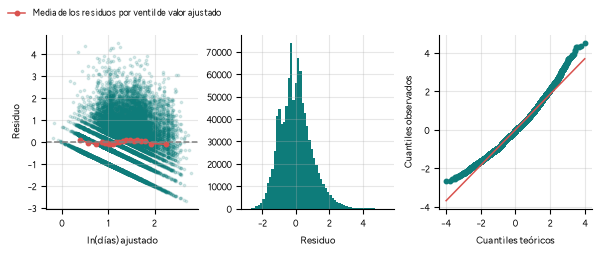

In [30]:
fig = figuras.residuos(m3.fittedvalues, m3.resid)
figuras.guardar(fig, "avance2_residuos", png=True)
plt.show()

# Base de las figuras: con ella y el JSON de cifras, `python3 paper/figuras.py` regenera los gráficos sin estimar modelos
columnas_fig = ["dias_estada", "log_dias", "edad", "tramo_edad", "capitulo", "region", "sexo", "establecimiento",
                "cirugia", "fallecido", "nacionalidad", "etnia", "prolongada", "ajuste_ln"]
df[columnas_fig].assign(residuo=m3.resid.values).to_parquet("results/base_figuras.parquet")


La curva de residuos medios ayuda a evaluar la forma funcional; la dispersión evalúa la varianza constante y el Q-Q describe desviaciones de normalidad. Las diagonales reflejan que los días son enteros. La inferencia clásica queda condicionada por estos diagnósticos.

### 3.7 Avance 1 contra Avance 2

Comparamos asociaciones bivariadas del Avance 1 con asociaciones ajustadas de M3. Las medidas tienen escalas distintas: interesa la dirección, el orden de relevancia y cuánto cambia la asociación al controlar por otros factores.

**Tabla complementaria.** Avance 1 contra Avance 2. Fuente: DEIS, MINSAL, egresos hospitalarios 2020; elaboración propia.

In [31]:
d74 = 74.5 - edad_prom
pct_edad = 100 * (np.exp(coef.loc["edad_c", "β"] * d74 + coef.loc["I(edad_c ** 2)", "β"] * d74 ** 2) - 1)
pct_cap = coef.loc[en_cap, "%Δ"]
w_cap, w_reg = ftest.loc["capitulo"], ftest.loc["region"]
print("Edad a los 74,5 años frente a la edad media: %Δ =", round(pct_edad, 1), "%")
fmt = lambda nombre: f"{es(coef.loc[nombre, '%Δ'], 1, True)} % [{es(coef.loc[nombre, '%Δ inf'], 1, True)}; {es(coef.loc[nombre, '%Δ sup'], 1, True)}]"
filas = [
    ("Establecimiento (SNSS)", f"r = {es(ef['establecimiento', 'días'], 2)}: el SNSS tiene más días", fmt("establecimiento: SNSS"), "Sigue asociado con más días después de controlar por diagnóstico, edad y región; consultar η² parcial"),
    ("Capítulo CIE-10", f"ε² = {es(ef['capitulo', 'días'], 2)}; V = {es(ef['capitulo', 'prolongada'], 2)}", f"F = {es(w_cap['F'], 0)} (gl = {w_cap['gl']:.0f}); %Δ de {es(pct_cap.min(), 1, True)} a {es(pct_cap.max(), 1, True)} % vs. K00-K93", "Comparar su η² parcial con los demás factores"),
    ("Sexo (hombre vs. mujer)", f"r = {es(ef['sexo', 'días'], 2)}: los hombres tienen más días", fmt("sexo: HOMBRE"), "Se mantiene la dirección (los hombres con más días), ahora con el diagnóstico controlado; el η² queda bajo 0,01: consultar η² parcial y contraste"),
    ("Edad", f"ρ = {es(ef['edad', 'días'], 2)}: a más edad, más días", f"{es(pct_edad, 1, True)} % a los 74,5 años vs. la edad media", "Sigue subiendo con la edad, con la curva ajustada casi recta; consultar η² parcial. La parábola no recoge el alza de los menores de un año. ρ es una correlación de rangos de a pares y el % es un cambio ajustado entre dos edades: no son la misma medida"),
    ("Cirugía (sí)", f"r = {es(ef['cirugia', 'días'], 2)}: los no operados tienen más días (mediana 4 contra 2)", fmt("cirugia: Sí"), "Misma dirección (los operados tienen menos días que los no operados), pero el η² queda bajo 0,01: consultar η² parcial. La diferencia de a pares posiblemente venía del capítulo (capítulo y cirugía tienen V = 0,43)"),
    ("Fallecido (sí)", f"r = {es(ef['fallecido', 'días'], 2)}: los fallecidos tienen más días", fmt("fallecido: Sí"), "De a pares tenía más días; con el resto controlado el η² queda bajo 0,01: consultar η² parcial. Posiblemente buena parte se asocia con diagnóstico y edad"),
    ("Región", f"ε² = {es(ef['region', 'días'], 3)}", f"F = {es(w_reg['F'], 1)} (gl = {w_reg['gl']:.0f}); %Δ de {es(coef.loc[en_reg, '%Δ'].min(), 1, True)} a {es(coef.loc[en_reg, '%Δ'].max(), 1, True)} % vs. Santiago", "De a pares casi no se veía y al controlar el η² sigue bajo 0,01: significativa como conjunto, no relevante. Aisén es la más baja"),
]
e2p = {"Establecimiento (SNSS)": "establecimiento", "Capítulo CIE-10": "capítulo", "Sexo (hombre vs. mujer)": "sexo", "Edad": "edad (edad y edad²)",
       "Cirugía (sí)": "cirugía", "Fallecido (sí)": "fallecido", "Región": "región"}
e2txt = lambda nombre: f"{es(parciales.loc[e2p[nombre], 'η² parcial'], 4)} ({parciales.loc[e2p[nombre], 'efecto (Cohen)']})"
tabla = "| Factor | Avance 1 (de a pares, quién tiene más días) | Avance 2 (modelo conjunto, %Δ en la media geométrica [IC 95 %]) | η² parcial (Cohen) | Qué cambia |\n|---|---|---|---|---|\n"
tabla += "\n".join(f"| {a} | {b} | {c} | {e2txt(a)} | {d} |" for a, b, c, d in filas)
display(Markdown(tabla))

Edad a los 74,5 años frente a la edad media: %Δ = 31.1 %


| Factor | Avance 1 (de a pares, quién tiene más días) | Avance 2 (modelo conjunto, %Δ en la media geométrica [IC 95 %]) | η² parcial (Cohen) | Qué cambia |
|---|---|---|---|---|
| Establecimiento (SNSS) | r = −0,37: el SNSS tiene más días | +70,0 % [+69,1; +70,8] | 0,0409 (pequeño) | Sigue asociado con más días después de controlar por diagnóstico, edad y región; consultar η² parcial |
| Capítulo CIE-10 | ε² = 0,12; V = 0,25 | F = 3.867 (gl = 20); %Δ de −31,9 a +214,8 % vs. K00-K93 | 0,0740 (mediano) | Comparar su η² parcial con los demás factores |
| Sexo (hombre vs. mujer) | r = 0,14: los hombres tienen más días | +11,3 % [+10,9; +11,8] | 0,0026 (menor que pequeño) | Se mantiene la dirección (los hombres con más días), ahora con el diagnóstico controlado; el η² queda bajo 0,01: consultar η² parcial y contraste |
| Edad | ρ = 0,25: a más edad, más días | +31,1 % a los 74,5 años vs. la edad media | 0,0347 (pequeño) | Sigue subiendo con la edad, con la curva ajustada casi recta; consultar η² parcial. La parábola no recoge el alza de los menores de un año. ρ es una correlación de rangos de a pares y el % es un cambio ajustado entre dos edades: no son la misma medida |
| Cirugía (sí) | r = 0,22: los no operados tienen más días (mediana 4 contra 2) | −2,8 % [−3,2; −2,3] | 0,0002 (menor que pequeño) | Misma dirección (los operados tienen menos días que los no operados), pero el η² queda bajo 0,01: consultar η² parcial. La diferencia de a pares posiblemente venía del capítulo (capítulo y cirugía tienen V = 0,43) |
| Fallecido (sí) | r = −0,29: los fallecidos tienen más días | +6,3 % [+5,2; +7,3] | 0,0001 (menor que pequeño) | De a pares tenía más días; con el resto controlado el η² queda bajo 0,01: consultar η² parcial. Posiblemente buena parte se asocia con diagnóstico y edad |
| Región | ε² = 0,002 | F = 310,1 (gl = 15); %Δ de −29,8 a +0,3 % vs. Santiago | 0,0048 (menor que pequeño) | De a pares casi no se veía y al controlar el η² sigue bajo 0,01: significativa como conjunto, no relevante. Aisén es la más baja |

Las correlaciones y tamaños de efecto bivariados no son comparables numéricamente con los coeficientes ajustados. La tabla permite distinguir asociaciones que se mantienen de aquellas que se atenúan al incorporar el resto de los factores. Esa atenuación es compatible con información compartida entre variables, pero no prueba un mecanismo causal.

### 3.8 Sensibilidad a la especificación: edad e interacciones

Conservamos M3 como modelo principal para interpretar asociaciones ajustadas y contrastamos tres especificaciones alternativas sobre la base completa:

- M4 sustituye edad y edad² por los 11 tramos de edad, con 40 a 49 años de referencia. M3 está anidado en M4 porque la edad toma los puntos medios de esos tramos.
- M5 añade capítulo × establecimiento para examinar si la asociación con el establecimiento varía entre diagnósticos.
- M6 añade tramo de edad × establecimiento para examinar heterogeneidad según edad.

Comparamos BIC, F parcial y η² parcial. Un BIC menor indica preferencia relativa dentro de este conjunto; una mejora pequeña no debe interpretarse como relevancia sustantiva. El análisis es exploratorio y no identifica efectos causales.

**Tabla D1 (informe).** Especificaciones M3 a M6 en la base completa.

In [32]:
tr = "C(tramo_edad, Treatment('40 a 49'))"
f4 = f"log_dias ~ {cap} + C(cirugia) + C(fallecido) + {tr} + C(sexo, Treatment('MUJER')) + C(establecimiento) + {reg}"
f5 = f4 + f" + {cap}:C(establecimiento)"           # M5: capítulo × establecimiento
f6 = f5 + f" + {tr}:C(establecimiento)"             # M6: tramo de edad × establecimiento
cand = [m3] + [smf.ols(f, df).fit() for f in (f4, f5, f6)]
nombres = ["M3", "M4", "M5", "M6"]

filas = []
for i, (n, m) in enumerate(zip(nombres, cand)):
    fila = {"modelo": n, "k": int(m.df_model) + 1, "R² aj.": m.rsquared_adj, "AIC": m.aic, "BIC": m.bic}
    if i > 0:
        a = anova_lm(cand[i - 1], m)
        fila.update({"Δ BIC": m.bic - cand[i - 1].bic, "F parcial": a["F"].iloc[1], "gl": int(a["df_diff"].iloc[1]),
                     "valor-p": a["Pr(>F)"].iloc[1], "η² parcial": (m.rsquared - cand[i - 1].rsquared) / (1 - cand[i - 1].rsquared)})
    filas.append(fila)
tabla_mejoras = pd.DataFrame(filas).set_index("modelo")
preferido_bic = nombres[int(np.argmin([m.bic for m in cand]))]
print("Especificación con menor BIC:", preferido_bic)
tabla_mejoras.round(4)

Especificación con menor BIC: M6


,k,R² aj.,AIC,BIC,Δ BIC,F parcial,gl,valor-p,η² parcial
modelo,,,,,,,,,
M3,42,0.1980,2.600604e+06,2.601099e+06,NaN,NaN,NaN,NaN,NaN
M4,50,0.2019,2.595922e+06,2.596511e+06,-4587.9818,588.6778,8.0,0.0,0.0048
M5,70,0.2140,2.581149e+06,2.581973e+06,-14537.8842,746.3192,20.0,0.0,0.0152
M6,80,0.2146,2.580368e+06,2.581310e+06,-663.0689,80.1165,10.0,0.0,0.0008


La tabla cuantifica el aporte de cada cambio de especificación. El η² parcial permite distinguir mejoras pequeñas de cambios sustantivos, incluso si los contrastes son significativos. Si las interacciones aportan, la asociación entre establecimiento y duración depende del grupo considerado; el coeficiente de M3 resume esa heterogeneidad.

**Comparación:** M4: R² ajustado = 0,202, ΔBIC = -4.588, η² parcial = 0,0048; M5: R² ajustado = 0,214, ΔBIC = -14.538, η² parcial = 0,0152; M6: R² ajustado = 0,215, ΔBIC = -663, η² parcial = 0,0008. El menor BIC corresponde a M6.


Las diferencias de ajuste describen sensibilidad a la forma funcional. M3 se mantiene como referencia para interpretar asociaciones promedio y M4 a M6 permiten examinar sus restricciones. La variabilidad restante podría relacionarse con gravedad, comorbilidades u otros factores no observados, pero estos datos no permiten comprobarlo.

**Sensibilidad a la inclusión de nacionalidad y etnia.** El Avance 1 seleccionó siete factores por BIC. Comparamos M3 con una versión que añade nacionalidad y etnia, usando todos los egresos, para evaluar si su exclusión altera apreciablemente el ajuste. Esto no equivale a repetir todo el procedimiento original de selección ni demuestra ausencia de asociación.

**Tabla complementaria.** M3 y M3 ampliado con nacionalidad y etnia, base completa.

In [33]:
m3x = smf.ols(f3 + " + C(nacionalidad) + C(etnia)", df).fit()
a = anova_lm(m3, m3x)
sensibilidad_variables = pd.DataFrame({"k": [int(m3.df_model) + 1, int(m3x.df_model) + 1], "R² aj.": [m3.rsquared_adj, m3x.rsquared_adj],
                     "BIC": [m3.bic, m3x.bic]}, index=["M3", "M3 + nacionalidad + etnia"])
sensibilidad_variables["F parcial"] = [np.nan, a["F"].iloc[1]]
sensibilidad_variables["valor-p"] = [np.nan, a["Pr(>F)"].iloc[1]]
sensibilidad_variables["η² parcial"] = [np.nan, (m3x.rsquared - m3.rsquared) / (1 - m3.rsquared)]
sensibilidad_variables.round(5)

,k,R² aj.,BIC,F parcial,valor-p,η² parcial
M3,42,0.19799,2.601099e+06,NaN,NaN,NaN
M3 + nacionalidad + etnia,44,0.19800,2.601112e+06,7.49421,0.00056,0.00002


Interpretamos conjuntamente el cambio de BIC, R² ajustado y η² parcial. Si el aporte es pequeño, su exclusión resulta compatible con una especificación parsimoniosa, aunque el contraste sea significativo. Los contrastes posteriores a selección de variables tienen un alcance exploratorio.

Al incorporar nacionalidad y etnia, ΔBIC = 12,6 y η² parcial = 0,00002. El BIC favorece conservar M3, pero el tamaño del aporte queda por debajo de 0,01. Esta comparación describe la sensibilidad del ajuste y no altera el foco interpretativo en los siete factores originales.


### 3.9 Selección forward de factores para el modelo de duración

Como contraste de la selección hacia atrás del Avance 1, aplicamos una selección forward a la regresión lineal de ln(días) sobre los mismos 968.098 egresos, usando **BIC** como criterio de entrada y parada. Partimos del intercepto; en cada paso probamos añadir cada factor aún ausente, elegimos el modelo con menor BIC y nos detenemos si ninguno mejora el BIC anterior. Un factor categórico entra con todas sus indicadoras y la edad entra con sus dos términos para respetar la estructura de M3.

Calculamos los ajustes candidatos a partir de los productos cruzados de la matriz de diseño de M3. Para cada subconjunto, resolver las ecuaciones normales reproduce el ajuste OLS de esas columnas sin reconstruir una matriz de casi un millón de filas en cada paso. Contrastamos el resultado final con M3 para verificar la equivalencia numérica. Esta búsqueda es exploratoria y dependiente del criterio BIC; los valores-p posteriores a la selección no son pruebas confirmatorias independientes.

**Tabla D2 (informe).** Recorrido forward por factores completos.

In [34]:
# Selección forward por factores completos del modelo M3.
from scipy.stats import f as dist_f

factores_forward = {
    "capítulo": cap,
    "cirugía": "C(cirugia)",
    "condición de egreso": "C(fallecido)",
    "edad y edad²": ["edad_c", "I(edad_c ** 2)"],
    "sexo": "C(sexo, Treatment('MUJER'))",
    "establecimiento": "C(establecimiento)",
    "región": reg,
}
nombres_columnas = m3.model.exog_names
columnas_factor = {}
for nombre, termino in factores_forward.items():
    if isinstance(termino, str): termino = [termino]
    columnas_factor[nombre] = [j for t in termino for j, col in enumerate(nombres_columnas) if col == t or col.startswith(t + "[")]
assert set(sum(columnas_factor.values(), [0])) == set(range(m3.model.exog.shape[1]))

X_forward = m3.model.exog
y_forward = m3.model.endog
gram = X_forward.T @ X_forward
xy = X_forward.T @ y_forward
yy = y_forward @ y_forward
n_forward = len(y_forward)
tss_forward = m3.centered_tss
def evaluar_factores(nombres):
    cols = [0] + [j for nombre in nombres for j in columnas_factor[nombre]]
    beta = np.linalg.solve(gram[np.ix_(cols, cols)], xy[cols])
    sse = yy - beta @ xy[cols]
    k = len(cols)
    bic = n_forward * (np.log(2*np.pi) + 1 + np.log(sse/n_forward)) + k*np.log(n_forward)
    r2 = 1 - sse/tss_forward
    r2_aj = 1 - (1-r2)*(n_forward-1)/(n_forward-k)
    return {"SSE":sse,"k":k,"BIC":bic,"R² ajustado":r2_aj}

seleccionados=[]
actual=evaluar_factores(seleccionados)
pasos_forward=[{"paso":0,"entra":"intercepto","factores incluidos":"ninguno",**actual,"ΔBIC":np.nan,"F parcial":np.nan,"valor-p":np.nan}]
alternativas_forward=[]
for paso in range(1,len(factores_forward)+1):
    opciones=[(nombre,evaluar_factores(seleccionados+[nombre])) for nombre in factores_forward if nombre not in seleccionados]
    opciones.sort(key=lambda item:item[1]["BIC"])
    elegido,nuevo=opciones[0]
    alternativas_forward.append({"paso":paso,"opciones BIC":{nombre:fit["BIC"] for nombre,fit in opciones}})
    if nuevo["BIC"] >= actual["BIC"]: break
    gl=nuevo["k"]-actual["k"]
    F=((actual["SSE"]-nuevo["SSE"])/gl)/(nuevo["SSE"]/(n_forward-nuevo["k"]))
    seleccionados.append(elegido)
    pasos_forward.append({"paso":paso,"entra":elegido,"factores incluidos":", ".join(seleccionados),
                          **nuevo,"ΔBIC":nuevo["BIC"]-actual["BIC"],"F parcial":F,
                          "valor-p":dist_f.sf(F,gl,n_forward-nuevo["k"])})
    actual=nuevo

tabla_forward=pd.DataFrame(pasos_forward).set_index("paso")
assert abs(evaluar_factores(list(factores_forward))["BIC"]-m3.bic)<0.1
print("Factores seleccionados:", ", ".join(seleccionados))
print("Factores descartados:", ", ".join(n for n in factores_forward if n not in seleccionados) or "ninguno")
tabla_forward_mostrar=tabla_forward.drop(columns="SSE").copy()
tabla_forward_mostrar["valor-p"] = tabla_forward_mostrar["valor-p"].map(lambda p: "no aplica" if pd.isna(p) else ("<0,001" if p<0.001 else f"{p:.3f}"))
tabla_forward_mostrar.round(3)

Factores seleccionados: capítulo, establecimiento, edad y edad², región, sexo, cirugía, condición de egreso
Factores descartados: ninguno


,entra,factores incluidos,k,BIC,R² ajustado,ΔBIC,F parcial,valor-p
paso,,,,,,,,
0,intercepto,ninguno,1,2814165.529,-0.000,NaN,NaN,no aplica
1,capítulo,capítulo,21,2685110.586,0.125,-129054.944,6918.215,"<0,001"
2,establecimiento,"capítulo, establecimiento",22,2643746.264,0.162,-41364.321,42274.162,"<0,001"
3,edad y edad²,"capítulo, establecimiento, edad y edad²",24,2608361.699,0.192,-35384.566,18033.440,"<0,001"
4,región,"capítulo, establecimiento, edad y edad², región",39,2603932.090,0.196,-4429.609,309.819,"<0,001"
5,sexo,"capítulo, establecimiento, edad y edad², regió...",40,2601374.303,0.198,-2557.787,2574.882,"<0,001"
6,cirugía,"capítulo, establecimiento, edad y edad², regió...",41,2601224.127,0.198,-150.176,163.966,"<0,001"
7,condición de egreso,"capítulo, establecimiento, edad y edad², regió...",42,2601099.216,0.198,-124.911,138.698,"<0,001"


El recorrido muestra el orden de incorporación y cuánto baja el BIC en cada paso. El F parcial describe el incremento de ajuste entre dos modelos anidados; el criterio de parada es el BIC.

**Tabla complementaria.** Comparación del modelo elegido por forward con M3 completo.

**Resultado.** El recorrido incorporó, en orden, capítulo, establecimiento, edad con edad², región, sexo, cirugía y condición de egreso. Los siete pasos redujeron el BIC, así que bajo este criterio no se descarta ningún factor y el modelo final coincide con M3. El mayor descenso ocurrió al incorporar capítulo (ΔBIC = −129.055) y los menores fueron cirugía (−150) y condición de egreso (−125). Los tres primeros factores ya llevan el R² ajustado a 0,192.

In [35]:
comparacion_forward=pd.DataFrame([
    {"modelo":"forward", "factores":len(seleccionados),**{k:actual[k] for k in ["k","BIC","R² ajustado"]}},
    {"modelo":"M3 completo", "factores":len(factores_forward),"k":int(m3.df_model)+1,
     "BIC":m3.bic,"R² ajustado":m3.rsquared_adj},
]).set_index("modelo")
comparacion_forward["ΔBIC vs. M3"] = comparacion_forward["BIC"]-m3.bic
comparacion_forward.round(4)

,factores,k,BIC,R² ajustado,ΔBIC vs. M3
modelo,,,,,
forward,7,42,2.601099e+06,0.198,0.0
M3 completo,7,42,2.601099e+06,0.198,0.0


La selección por BIC se interpreta junto con el aporte ajustado de cada factor y los coeficientes de M3. Con este tamaño de base, BIC puede retener diferencias muy pequeñas, así que conservar los siete factores no implica que todos pesen lo mismo. La selección tampoco establece causalidad.

En esta base, forward conserva los siete factores y reproduce el BIC y el R² ajustado de M3. El recorrido no examina los 127 subconjuntos posibles. Los η² parciales de capítulo, establecimiento y edad siguen siendo los más altos, y los de cirugía y condición de egreso son menores que 0,001.

## 4. Discusión y conclusiones

### 4.1 Respuesta a la pregunta y contraste de las hipótesis

La F global de M3 (F = 5.830; p < 0,001) rechaza la H₀ general. Por grupo de factores (tabla 8 del informe):

| Hipótesis | Prueba en M3 | Decisión | Relevancia (η² parcial ≥ 0,01) |
|---|---|---|---|
| H₀a clínicos | Capítulo F = 3.867; cirugía F = 157; fallecido F = 139 | Rechaza H₀a | Capítulo sí (0,074). Cirugía y fallecido no (0,0002 y 0,0001) |
| H₀b demográficos | Edad +0,89 % por año (t = 186,0); sexo F = 2.533 | Rechaza H₀b | Edad sí (0,035). Sexo no (0,0026) |
| H₀c sistema de salud | SNSS +70,0 %, F = 41.287; región F = 310 | Rechaza H₀c | Establecimiento sí (0,041). Región no (0,0048) |
| H₀d sensibilidad | Nacionalidad y etnia, F = 7,49 (p = 0,0006) | Rechaza H₀d | No (0,00002); el BIC sube 12,6 |

Las cuatro nulas se rechazan, pero solo H₁a, H₁b y H₁c quedan respaldadas por un factor con efecto relevante: el capítulo, la edad y el establecimiento, respectivamente. El ranking por η² parcial (tabla 7 del informe) los pone en ese orden: capítulo, establecimiento y edad, y la selección forward por BIC los incorpora en el mismo orden.

### 4.2 Relación con la literatura

El peso del diagnóstico coincide con la lógica de los GRD (Fetter et al., 1980). El establecimiento y la edad se mantienen asociados al controlar por diagnóstico, como hallaron Freitas et al. (2012) para las estadías extremas dentro de un mismo GRD en Portugal. Olivares-Tirado (2020), que estudió las hospitalizaciones de 60 días o más en mayores de 60 años, asoció las estadías más largas con enfermedades mentales y demencias, lo que calza con que los trastornos mentales tengan el mayor aumento en M3. Que el R² quede en 0,198 es compatible con que la gravedad, que el GRD mide y aquí solo aproxima el capítulo, explique otra parte de la duración, aunque esta base no permite comprobarlo.

### 4.3 Pares frente a modelo conjunto

El establecimiento mantiene su peso al ajustar: de a pares tenía un efecto mediano sobre los días (r = −0,37) y en M3 los egresos del SNSS tienen una media geométrica 70,0 % mayor. En el chi-cuadrado su V es solo 0,08, pero esa prueba mira la estadía prolongada, que es poco frecuente (9,4 %), y con un resultado raro una diferencia grande deja una asociación chica en la tabla.

La cirugía y la condición de egreso, en cambio, se achican al ajustar. De a pares los egresos sin cirugía duran más (r = 0,22) y los fallecidos también (r = −0,29); en M3 la cirugía queda en −2,8 % y el fallecido en +6,3 %, con η² parcial de 0,0002 y 0,0001. Las dos comparten información con el capítulo (V = 0,43 y 0,26), así que de a pares probablemente reflejan en qué diagnósticos se opera o se muere. Ninguna de estas asociaciones es causal: el SNSS podría concentrar casos más graves, pero la base no trae gravedad para separarlo.

### 4.4 Limitaciones

- La unidad es el egreso, y la base no trae GRD, gravedad, comorbilidades completas ni identificadores de paciente y hospital. Los reingresos y la agrupación por hospital cuestionan la independencia, así que los valores-p y los intervalos pueden quedar optimistas.
- El filtro de 365 días puede excluir estadías legítimas excepcionalmente largas, y no reestimamos los modelos sin ese filtro. La edad viene en tramos de 10 años, así que sus pruebas y su curva usan solo 11 valores.
- Hay sesgo de selección: la base cubre solo a beneficiarios FONASA, que no representan a los afiliados a isapres, y 2020 tuvo 19 % menos egresos que 2019 (Barahona et al., 2021), con menos cirugías electivas. Las asociaciones no se extrapolan automáticamente a otros años ni a toda la población.
- La comparación de especificaciones y la selección previa de variables vuelven exploratoria parte del análisis.
- La condición de egreso se conoce recién al alta, así que los modelos no sirven como herramienta de decisión al ingreso.

### 4.5 Conclusiones

El diagnóstico, el tipo de establecimiento y la edad son los factores más asociados a cuántos días ocupa un egreso. Frente a los egresos de establecimientos fuera del SNSS, el SNSS tiene 70,0 % más de media geométrica de días. Sexo, cirugía, condición de egreso y región tienen aportes ajustados menores que un efecto pequeño. La regresión lineal explica el 19,8 % de la variación de ln(días), y como máximo el 21,5 % con las especificaciones alternativas; parte de lo que falta probablemente es gravedad, que la base no trae.

Para la gestión de camas, los trastornos mentales (+214,8 % frente al digestivo) y la red SNSS son los primeros lugares donde mirar. La duración sube con la edad desde los 20 años, y los menores de un año tienen una mediana de 4 días, por sobre los 2 de los adultos jóvenes. Los resultados no permiten atribuir causalidad ni decidir sobre un paciente.


### Síntesis numérica

El resumen y el archivo de cifras siguientes se generan a partir de los ajustes sobre la base completa. Las tablas largas de los anexos del informe las escribe `paper/gen_anexos.py` a partir de ese archivo.


In [36]:
def num(o):
    return o.item() if hasattr(o, "item") else str(o)

resumen = f"""**Resultados sobre {len(df):,} egresos.** M3: R² ajustado = {m3.rsquared_adj:.3f}; M6: R² ajustado = {cand[-1].rsquared_adj:.3f}. La especificación con menor BIC es {preferido_bic}. Estos valores describen el ajuste en la base completa.

**Duración:** los tres factores con mayor η² parcial son {', '.join(f'{idx} ({row["η² parcial"]:.3f})' for idx, row in parciales.sort_values('η² parcial', ascending=False).head(3).iterrows())}. El cambio ajustado asociado a SNSS es {coef.loc['establecimiento: SNSS', '%Δ']:.1f} % en media geométrica; para hombres frente a mujeres es {coef.loc['sexo: HOMBRE', '%Δ']:.1f} %."""
display(Markdown(resumen))
cifras = {
    "enfoque": "analítico, observacional, base completa, sin particiones",
    "n": len(df), "n_columnas_base": n_columnas, "n_comunas": n_comunas,
    "excluidos_mas_365": int((bruta > 365).sum()), "pct_excluidos": 100 * (bruta > 365).mean(),
    "percentil_90_dias": df["dias_estada"].quantile(0.9), "ln_n": np.log(len(df)),
    "interv_q": tabla_intervq.round(2).to_dict("index"),
    "base_analitica": base_analitica.to_dict("index"),
    "descriptivos": desc.round(4).to_dict("index"),
    "pct_prolongadas": pct_egresos, "pct_dias_cama": pct_dias,
    "atipicos": atip.round(4).to_dict("index"), "comparacion_robustez": comp.round(4).to_dict("index"),
    "pct_diag2_nulo": pct_diag2,
    "cramer_variables": {f"{a} | {b}": v for (a, b), v in pares.round(4).items()},
    "normalidad": normalidad.round(6).to_dict("index"),
    "pares": pruebas_pares.round(6).to_dict("records"),
    "pares_resumen": resumen_pares.to_dict("records"),
    "n_pruebas_pares": n_pruebas,
    "posthoc_holm": posthoc,
    "pct_prolongadas_por_grupo": {k: v.round(2).to_dict() for k, v in pct_prolongadas_grupo.items()},
    "contingencia": {k: {n: {c: int(x) for c, x in fila.items()} for n, fila in v.to_dict("index").items()} for k, v in contingencia.items()},
    "mediana_dias_por_tramo": mediana_tramo.to_dict(),
    "modelos": tabla_modelos.round(6).to_dict("index"), "anova": anova.round(6).to_dict("index"),
    "eta2_bloques": bloques.set_index("comparación").round(6).to_dict("index"),
    "eta2_parciales": parciales.round(6).to_dict("index"),
    "coef": coef.round(6).to_dict("index"), "hc3_resumen": hc3_resumen,
    "ftest": ftest.round(5).to_dict("index"),
    "exp_intercepto": np.exp(coef.loc["Intercept", "β"]),
    "pct_edad_74_5": pct_edad,
    "edad_observada_ajustada": por_tramo.round(4).to_dict("index"),
    "deciles": cal.round(4).to_dict("index"),
    "vif_max": vif.max(), "rango_X": int(rango_x),
    "sd_residuos_cuartil": sd_cuartil.to_dict(), "asimetria_residuos": asim_r, "curtosis_residuos": curt_r,
    "especificaciones": tabla_mejoras.round(5).to_dict("index"),
    "especificacion_menor_bic": preferido_bic,
    "sensibilidad_variables": sensibilidad_variables.round(6).to_dict("index"),
    "forward_pasos": tabla_forward.round(6).to_dict("index"),
    "forward_comparacion": comparacion_forward.round(6).to_dict("index"),
    "forward_factores": seleccionados,
}
os.makedirs("results", exist_ok=True)
with open("results/cifras_avance2_v8.json", "w", encoding="utf-8") as f:
    json.dump(cifras, f, default=num, ensure_ascii=False, indent=2)
print("Cifras guardadas:", len(cifras), "claves")


**Resultados sobre 968,098 egresos.** M3: R² ajustado = 0.198; M6: R² ajustado = 0.215. La especificación con menor BIC es M6. Estos valores describen el ajuste en la base completa.

**Duración:** los tres factores con mayor η² parcial son capítulo (0.074), establecimiento (0.041), edad (edad y edad²) (0.035). El cambio ajustado asociado a SNSS es 70.0 % en media geométrica; para hombres frente a mujeres es 11.3 %.

Cifras guardadas: 47 claves


### Verificación de las cifras del informe

La celda siguiente compara cada cifra que cita el informe con el valor calculado en este notebook, redondeado a los decimales que usa el informe, y se detiene si alguna no coincide. También comprueba que no se haya cargado ninguna biblioteca de aprendizaje automático.


In [37]:
esperado = [  # (cifra, valor calculado, valor del informe, decimales del informe)
    # datos y depuración
    ("n", len(df), 968098, 0), ("columnas", n_columnas, 18, 0), ("comunas", n_comunas, 344, 0),
    ("excluidos", (bruta > 365).sum(), 397, 0), ("% excluidos", 100 * (bruta > 365).mean(), 0.04, 2),
    ("p90 días", df["dias_estada"].quantile(0.9), 15, 0), ("ln n", np.log(len(df)), 13.8, 1),
    ("INTERV_Q cesárea", tabla_intervq.loc["Cesárea (O82)", "% INTERV_Q = 1"], 97, 0),
    ("% prolongadas", pct_egresos, 9.4, 1), ("% días-cama", pct_dias, 47.1, 1), ("DIAG2 nulo", pct_diag2, 90.2, 1),
    # tabla 3
    ("media días", desc.loc["dias_estada", "mean"], 6.70, 2), ("mediana días", desc.loc["dias_estada", "median"], 3, 0),
    ("s días", desc.loc["dias_estada", "s"], 12.79, 2), ("asim días", desc.loc["dias_estada", "asimetría"], 9.04, 2),
    ("RIC días", desc.loc["dias_estada", "RIC"], 5, 2), ("Q1 días", desc.loc["dias_estada", "Q1"], 2, 0), ("Q3 días", desc.loc["dias_estada", "Q3"], 7, 0),
    ("media ln", desc.loc["log_dias", "mean"], 1.25, 2), ("mediana ln", desc.loc["log_dias", "median"], 1.10, 2),
    ("s ln", desc.loc["log_dias", "s"], 1.04, 2), ("asim ln", desc.loc["log_dias", "asimetría"], 0.68, 2), ("RIC ln", desc.loc["log_dias", "RIC"], 1.25, 2),
    ("media edad", desc.loc["edad", "mean"], 45.01, 2), ("mediana edad", desc.loc["edad", "median"], 44.50, 2),
    ("s edad", desc.loc["edad", "s"], 24.29, 2), ("asim edad", desc.loc["edad", "asimetría"], 0.01, 2), ("RIC edad", desc.loc["edad", "RIC"], 40, 2),
    # composición, Tukey y robustez
    ("% SNSS", 100 * (df["establecimiento"] == "SNSS").mean(), 81.8, 1), ("% mujeres", 100 * (df["sexo"] == "MUJER").mean(), 60.0, 1),
    ("% O00", 100 * (df["capitulo"] == "O00-O99").mean(), 20.4, 1), ("% K00", 100 * (df["capitulo"] == "K00-K93").mean(), 13.8, 1),
    ("% S00", 100 * (df["capitulo"] == "S00-T98").mean(), 9.8, 1),
    ("Tukey Ls", atip.loc["días", "Ls"], 14.5, 1), ("n > Ls", atip.loc["días", "n > Ls"], 99978, 0), ("% > Ls", atip.loc["días", "% > Ls"], 10.33, 2),
    ("media con >365", comp.iloc[0]["media"], 7.29, 2), ("s con >365", comp.iloc[0]["s"], 59.74, 2),
    ("mediana con >365", comp.iloc[0]["mediana"], 3, 0), ("MAD con >365", comp.iloc[0]["MAD"], 2, 0),
    # normalidad y pares (tabla 4 y §4.2)
    ("p AD días", normalidad.loc["dias_estada", "p AD"], 0.01, 2), ("p AD edad", normalidad.loc["edad", "p AD"], 0.01, 2),
    ("rho edad", ef["edad", "días"], 0.25, 2), ("r establecimiento", ef["establecimiento", "días"], -0.37, 2),
    ("r fallecido", ef["fallecido", "días"], -0.29, 2), ("r cirugía", ef["cirugia", "días"], 0.22, 2), ("r sexo", ef["sexo", "días"], 0.14, 2),
    ("r nacionalidad", ef["nacionalidad", "días"], 0.06, 2), ("r etnia", ef["etnia", "días"], -0.02, 2),
    ("eps2 capítulo", ef["capitulo", "días"], 0.12, 2), ("eps2 región", ef["region", "días"], 0.002, 3),
    ("V capítulo", ef["capitulo", "prolongada"], 0.25, 2), ("V tramo", ef["tramo_edad", "prolongada"], 0.16, 2),
    ("V fallecido", ef["fallecido", "prolongada"], 0.11, 2), ("V sexo", ef["sexo", "prolongada"], 0.10, 2),
    ("V establecimiento", ef["establecimiento", "prolongada"], 0.08, 2), ("V etnia", ef["etnia", "prolongada"], 0.004, 3),
    ("esperada mínima", pruebas_pares["esperada mínima"].min(), 175, 0),
    ("% prol. capítulo mín", pct_prolongadas_grupo["capitulo"].min(), 0.9, 1), ("% prol. capítulo máx", pct_prolongadas_grupo["capitulo"].max(), 35.6, 1),
    ("% prol. <1 año", pct_prolongadas_grupo["tramo_edad"]["menor de un año"], 15.4, 1),
    ("% prol. 20-29", pct_prolongadas_grupo["tramo_edad"]["20 a 29"], 3.5, 1), ("% prol. 70-79", pct_prolongadas_grupo["tramo_edad"]["70 a 79"], 15.4, 1),
    ("% prol. fallecido", pct_prolongadas_grupo["fallecido"]["Sí"], 25.3, 1), ("% prol. vivo", pct_prolongadas_grupo["fallecido"]["No"], 8.8, 1),
    ("% prol. hombre", pct_prolongadas_grupo["sexo"]["HOMBRE"], 13.1, 1), ("% prol. mujer", pct_prolongadas_grupo["sexo"]["MUJER"], 6.9, 1),
    ("% prol. SNSS", pct_prolongadas_grupo["establecimiento"]["SNSS"], 10.6, 1), ("% prol. no SNSS", pct_prolongadas_grupo["establecimiento"]["No SNSS"], 4.2, 1),
    ("mediana 20-29", mediana_tramo["20 a 29"], 2, 0), ("mediana 80-89", mediana_tramo["80 a 89"], 6, 0),
    ("mediana 90+", mediana_tramo["90 y más"], 6, 0), ("mediana <1", mediana_tramo["menor de un año"], 4, 0),
    ("V cap-cir", V.loc["capitulo", "cirugia"], 0.43, 2), ("V cap-sexo", V.loc["capitulo", "sexo"], 0.43, 2),
    ("V cir-estab", V.loc["cirugia", "establecimiento"], 0.28, 2), ("V cap-fall", V.loc["capitulo", "fallecido"], 0.26, 2),
    # tabla 5
    *[(f"R2aj {m}", tabla_modelos.loc[m, "R² aj."], v, 3) for m, v in [("M1", 0.132), ("M2", 0.162), ("M3", 0.198)]],
    *[(f"BIC {m}", tabla_modelos.loc[m, "BIC"], v, 0) for m, v in [("M0", 2814166), ("M1", 2676930), ("M2", 2643664), ("M3", 2601099)]],
    *[(f"dBIC {m}", tabla_modelos.loc[m, "Δ BIC"], v, 0) for m, v in [("M1", -137235), ("M2", -33266), ("M3", -42565)]],
    *[(f"F {m}", tabla_modelos.loc[m, "F parcial"], v, 0) for m, v in [("M1", 6717), ("M2", 11295), ("M3", 2734)]],
    *[(f"gl {m}", tabla_modelos.loc[m, "gl"], v, 0) for m, v in [("M1", 22), ("M2", 3), ("M3", 16)]],
    *[(f"eta2 {m}", tabla_modelos.loc[m, "η² parcial"], v, 3) for m, v in [("M1", 0.132), ("M2", 0.034), ("M3", 0.043)]],
    # tabla 7 (ranking)
    *[(f"R2 sin {f}", parciales.loc[f, "R² sin el factor"], v, 4) for f, v in [("capítulo", 0.1339), ("establecimiento", 0.1638), ("edad (edad y edad²)", 0.1692), ("región", 0.1942), ("sexo", 0.1959), ("cirugía", 0.1979), ("fallecido", 0.1979)]],
    *[(f"eta2p {f}", parciales.loc[f, "η² parcial"], v, 4) for f, v in [("capítulo", 0.0740), ("establecimiento", 0.0409), ("edad (edad y edad²)", 0.0347), ("región", 0.0048), ("sexo", 0.0026), ("cirugía", 0.0002), ("fallecido", 0.0001)]],
    # ANOVA y coeficientes (tabla 6, §4.4, §4.5)
    ("F global", m3.fvalue, 5830, 0), ("gl resid", m3.df_resid, 968056, 0), ("SS reg", m3.ess, 205399, 0), ("SS total", m3.centered_tss, 1037266, 0),
    ("exp intercepto", np.exp(coef.loc["Intercept", "β"]), 1.82, 2), ("edad media", edad_prom, 45.01, 2),
    *[(f"{c} {col}", coef.loc[c, col], v, d) for c, vals in {
        "capitulo: F00-F99": (1.147, 0.007, 0.010, 214.8, 210.4, 219.3), "capitulo: U00-U99": (0.880, 0.005, 0.006, 141.2, 138.6, 143.8),
        "capitulo: P00-P96": (0.805, 0.007, 0.009, 123.8, 120.5, 127.1), "capitulo: A00-B99": (0.643, 0.007, 0.009, 90.3, 87.5, 93.0),
        "capitulo: H00-H59": (-0.385, 0.014, 0.012, -31.9, -33.7, -30.1), "capitulo: Z00-Z99": (-0.356, 0.007, 0.007, -29.9, -30.9, -28.9),
        "cirugia: Sí": (-0.028, 0.002, 0.002, -2.8, -3.2, -2.3), "fallecido: Sí": (0.061, 0.005, 0.007, 6.3, 5.2, 7.3),
        "sexo: HOMBRE": (0.107, 0.002, 0.002, 11.3, 10.9, 11.8), "establecimiento: SNSS": (0.530, 0.003, 0.002, 70.0, 69.1, 70.8)}.items()
      for col, v, d in zip(cols_paper, vals, (3, 3, 3, 1, 1, 1))],
    *[(f"edad_c {col}", coef.loc["edad_c", col], v, d) for col, v, d in zip(cols_paper, (0.009, 0.000048, 0.000050, 0.89, 0.88, 0.90), (3, 6, 6, 2, 2, 2))],
    ("Aisén", pr.iloc[0], -29.8, 1), ("región mín sin Aisén", pr.iloc[1], -15.8, 1), ("región máx", pr.iloc[-1], 0.3, 1),
    ("F capítulo", ftest.loc["capitulo", "F"], 3867, 0), ("gl capítulo", ftest.loc["capitulo", "gl"], 20, 0),
    ("F región", ftest.loc["region", "F"], 310, 0), ("gl región", ftest.loc["region", "gl"], 15, 0), ("F establecimiento", ftest.loc["establecimiento", "F"], 41287, 0),
    ("edad 74,5", pct_edad, 31.1, 1), ("<1 año observada", por_tramo.loc[0.5, "log_dias"], 1.47, 2), ("<1 año ajustada", por_tramo.loc[0.5, "ajuste_ln"], 1.33, 2),
    ("HC3 razón mín", hc3_resumen["razon_min"], 0.80, 2), ("HC3 razón máx", hc3_resumen["razon_max"], 1.36, 2),
    ("F00 HC3 inf", coef.loc["capitulo: F00-F99", "%Δ HC3 inf"], 208.8, 1), ("F00 HC3 sup", coef.loc["capitulo: F00-F99", "%Δ HC3 sup"], 220.9, 1),
    # ajuste y supuestos (§4.5 y tabla C1)
    ("R2 M3", m3.rsquared, 0.198, 3), ("rango X", rango_x, 42, 0), ("VIF máx", vif.max(), 2.36, 2),
    ("sd Q1", sd_cuartil["Q1"], 0.713, 3), ("sd Q4", sd_cuartil["Q4"], 1.061, 3), ("asimetría resid", asim_r, 0.492, 3), ("curtosis resid", curt_r, 0.542, 3),
    *[(f"decil {d} {col}", cal.loc[d, col], v, dd) for d, vals in {1: (1.60, 1.66, 2), 2: (2.21, 2.14, 2), 3: (2.59, 2.50, 2), 4: (2.82, 2.61, 2), 5: (3.11, 2.96, 3),
        6: (3.57, 3.67, 3), 7: (4.18, 4.56, 4), 8: (4.88, 5.28, 5), 9: (5.73, 5.99, 6), 10: (8.05, 7.40, 8)}.items()
      for col, v, dd in zip(["ajustada (media geométrica)", "observada (media geométrica)", "observada (mediana)"], vals, (2, 2, 0))],
    # sensibilidad (§4.6 y tabla D1)
    *[(f"{m} {col}", tabla_mejoras.loc[m, col], v, d) for m, vals in {"M4": (0.202, -4588, 589, 8, 0.0048), "M5": (0.214, -14538, 746, 20, 0.0152), "M6": (0.215, -663, 80, 10, 0.0008)}.items()
      for col, v, d in zip(["R² aj.", "Δ BIC", "F parcial", "gl", "η² parcial"], vals, (3, 0, 0, 0, 4))],
    *[(f"k {m}", tabla_mejoras.loc[m, "k"], v, 0) for m, v in [("M3", 42), ("M4", 50), ("M5", 70), ("M6", 80)]],
    ("R2aj M3 (5)", sensibilidad_variables.iloc[0]["R² aj."], 0.19799, 5), ("R2aj M3+nac+etnia", sensibilidad_variables.iloc[1]["R² aj."], 0.19800, 5),
    ("dBIC nac+etnia", sensibilidad_variables.iloc[1]["BIC"] - sensibilidad_variables.iloc[0]["BIC"], 12.6, 1),
    ("eta2 nac+etnia", sensibilidad_variables.iloc[1]["η² parcial"], 0.000015, 6), ("F nac+etnia", sensibilidad_variables.iloc[1]["F parcial"], 7.49, 2),
    ("p nac+etnia", sensibilidad_variables.iloc[1]["valor-p"], 0.0006, 4),
    # forward (tabla D2)
    *[(f"forward {p} {col}", tabla_forward.loc[p, col], v, d) for p, vals in {1: (2685111, -129055, 0.125), 2: (2643746, -41364, 0.162), 3: (2608362, -35385, 0.192),
        4: (2603932, -4430, 0.196), 5: (2601374, -2558, 0.198), 6: (2601224, -150, 0.198), 7: (2601099, -125, 0.198)}.items()
      for col, v, d in zip(["BIC", "ΔBIC", "R² ajustado"], vals, (0, 0, 3))],
    # contraste de hipótesis (tabla 8)
    ("t edad", coef.loc["edad_c", "t"], 186.0, 1), ("F cirugía", ftest.loc["cirugia", "F"], 157, 0),
    ("F fallecido", ftest.loc["fallecido", "F"], 139, 0), ("F sexo", ftest.loc["sexo", "F"], 2533, 0),
    ("R2aj M6", tabla_mejoras.loc["M6", "R² aj."], 0.215, 3), ("% Δ F00", coef.loc["capitulo: F00-F99", "%Δ"], 214.8, 1),
    ("máximo días", bruta.max(), 16598, 0), ("capítulos", df["capitulo"].nunique(), 21, 0),
    ("regiones", df["region"].nunique(), 16, 0), ("nacionalidades", df["nacionalidad"].nunique(), 2, 0),
]
fallas = [f"{n}: notebook {float(v):.6g} | informe {p}" for n, v, p, d in esperado if abs(float(v) - p) > 0.5 * 10 ** -d + 1e-9]
print(f"Cifras del informe comparadas: {len(esperado)} | diferencias: {len(fallas)}")
print("\n".join(fallas))
assert not fallas, "hay cifras del notebook que no coinciden con el informe"
assert n_pruebas == 20 and pruebas_pares["valor-p"].max() < 0.0002
assert (normalidad[["p SW", "p KS"]] < 0.001).all().all()
assert max(pruebas_pares.set_index("variable").loc[["cirugia", "region", "nacionalidad", "etnia"]].query("prueba == 'Chi-cuadrado'")["efecto"]) < 0.06
assert pct_prolongadas_grupo["capitulo"].idxmin() == "O00-O99" and pct_prolongadas_grupo["capitulo"].idxmax() == "F00-F99"
assert posthoc == {"capitulo": {"pares": 210, "distintos": 202}, "region": {"pares": 120, "distintos": 104}}
assert hc3_resumen["cambios_significancia"] == 0
assert seleccionados == ["capítulo", "establecimiento", "edad y edad²", "región", "sexo", "cirugía", "condición de egreso"]
assert preferido_bic == "M6"
prohibidas = {"sklearn", "xgboost", "lightgbm", "catboost", "tensorflow", "torch", "keras"}
assert not prohibidas & {m.split(".")[0] for m in sys.modules}, "se cargó una biblioteca de aprendizaje automático"
print("Verificación completa: las cifras coinciden con el informe y no se usó ninguna biblioteca de aprendizaje automático.")

Cifras del informe comparadas: 290 | diferencias: 0



Verificación completa: las cifras coinciden con el informe y no se usó ninguna biblioteca de aprendizaje automático.


## Referencias


1. Cohen, J. (1988). *Statistical power analysis for the behavioral sciences* (2.ª ed.). Lawrence Erlbaum Associates.
2. Fetter, R. B., Shin, Y., Freeman, J. L., Averill, R. F., & Thompson, J. D. (1980). Case mix definition by diagnosis-related groups. *Medical Care, 18*(2 Suppl.), 1–53.
3. Freitas, A., Silva-Costa, T., Lopes, F., Garcia-Lema, I., Teixeira-Pinto, A., Brazdil, P., & Costa-Pereira, A. (2012). Factors influencing hospital high length of stay outliers. *BMC Health Services Research, 12*, Article 265. https://doi.org/10.1186/1472-6963-12-265
4. Kerby, D. S. (2014). The simple difference formula: An approach to teaching nonparametric correlation. *Comprehensive Psychology, 3*, 11.IT.3.1. https://doi.org/10.2466/11.IT.3.1
5. Lin, M., Lucas, H. C., & Shmueli, G. (2013). Too big to fail: Large samples and the p-value problem. *Information Systems Research, 24*(4), 906–917. https://doi.org/10.1287/isre.2013.0480
6. Olivares-Tirado, P. (2020). *Hospitalización social en adultos mayores en el sistema de salud de Chile* [Documento de trabajo]. Superintendencia de Salud. https://www.superdesalud.gob.cl/biblioteca-digital/hospitalizacion-social-en-adultos-mayores-en-el-sistema-de-salud-de-chile/
7. Raftery, A. E. (1995). Bayesian model selection in social research. *Sociological Methodology, 25*, 111–163. https://doi.org/10.2307/271063
8. Rodríguez, D. E., & González, G. J. (2017). *Principios de econometría*. Fondo Editorial ITM.